<a href="https://colab.research.google.com/github/gokulkumar2610-keep/Telco-Customer-Churn-Prediction/blob/main/Final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""Reusable churn-prediction pipeline (Colab friendly).

Usage in Colab:
    from churn_pipeline import ChurnPipeline
    pipe = ChurnPipeline(target="Churn", id_cols=["customerID"])
    metrics = pipe.run("/content/churn.csv")
"""
import logging
import os
import urllib.request

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report,
                             f1_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)
logger = logging.getLogger(__name__)


# ---------- helper functions ----------
def load_data(path: str) -> pd.DataFrame:
    """Load a CSV file, logging and re-raising any failure."""
    try:
        df = pd.read_csv(path)
        logger.info("Loaded %s rows x %s cols from %s", *df.shape, path)
        return df
    except FileNotFoundError as e:
        logger.error("File not found: %s", path)
        raise
    except pd.errors.EmptyDataError as e:
        logger.error("File is empty: %s", path)
        raise


def clean_data(df: pd.DataFrame, target: str, id_cols=None) -> pd.DataFrame:
    """Drop IDs/duplicates, fix numeric-looking text, encode the target."""
    df = df.copy()
    df = df.drop(columns=[c for c in (id_cols or []) if c in df.columns])
    before = len(df)
    df = df.drop_duplicates()
    logger.info("Removed %s duplicate rows", before - len(df))

    # Convert object columns that are really numbers (e.g. TotalCharges)
    for col in df.select_dtypes(include="object").columns:
        if col == target:
            continue
        converted = pd.to_numeric(df[col], errors="coerce")
        if converted.notna().mean() > 0.9:  # mostly numeric -> treat as numeric
            df[col] = converted

    if target not in df.columns:
        raise KeyError(f"Target column '{target}' not found")
    if df[target].dtype == "object":
        df[target] = df[target].str.strip().str.lower().map({"yes": 1, "no": 0})
    df = df.dropna(subset=[target])
    logger.info("Cleaned data shape: %s", df.shape)
    return df


def evaluate_model(model, X_test, y_test) -> dict:
    """Return key classification metrics and log a full report."""
    preds = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    metrics = {
        "accuracy": accuracy_score(y_test, preds),
        "f1": f1_score(y_test, preds),
        "roc_auc": roc_auc_score(y_test, proba),
    }
    logger.info("Metrics: %s", {k: round(v, 3) for k, v in metrics.items()})
    logger.info("\n%s", classification_report(y_test, preds))
    return metrics


# ---------- pipeline class ----------
class ChurnPipeline:
    def __init__(self, target="Churn", id_cols=None, test_size=0.2, seed=42):
        self.target = target
        self.id_cols = id_cols or []
        self.test_size = test_size
        self.seed = seed
        self.model = None

    def _build_model(self, X: pd.DataFrame) -> Pipeline:
        num = X.select_dtypes(include="number").columns.tolist()
        cat = X.select_dtypes(exclude="number").columns.tolist()
        prep = ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                              ("sc", StandardScaler())]), num),
            ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                              ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
        ])
        return Pipeline([
            ("prep", prep),
            ("clf", RandomForestClassifier(n_estimators=200, random_state=self.seed)),
        ])

    def fit(self, X: pd.DataFrame, y: pd.Series):
        logger.info("Training model on %s rows", len(X))
        self.model = self._build_model(X)
        self.model.fit(X, y)
        logger.info("Training complete")
        return self

    def predict(self, X: pd.DataFrame):
        if self.model is None:
            raise RuntimeError("Call fit() before predict()")
        return self.model.predict(X)

    def predict_proba(self, X: pd.DataFrame):
        if self.model is None:
            raise RuntimeError("Call fit() before predict_proba()")
        return self.model.predict_proba(X)[:, 1]

    def run(self, path: str) -> dict:
        """End-to-end: load -> clean -> split -> fit -> evaluate."""
        df = clean_data(load_data(path), self.target, self.id_cols)
        X, y = df.drop(columns=[self.target]), df[self.target]
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=self.test_size, stratify=y, random_state=self.seed
        )
        self.fit(X_train, y_train)
        return evaluate_model(self.model, X_test, y_test)


if __name__ == "__main__":
    # Download sample dataset if not present
    csv_path = "churn.csv"
    if not os.path.exists(csv_path):
        logger.info("%s not found. Downloading a sample Telco Churn dataset...", csv_path)
        url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
        urllib.request.urlretrieve(url, csv_path)

    ChurnPipeline(id_cols=["customerID"]).run(csv_path)

In [ ]:
   logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)

In [ ]:
"""Module 3: NumPy & Pandas - clean the IBM Telco Customer Churn data.

Usage in Colab:
    from telco_cleaning import *
    raw = load_data("/content/churn.csv")
    df = clean_telco(raw)
    outliers = flag_outliers(df, ["MonthlyCharges", "TotalCharges", "tenure"])
    tables = build_summary_tables(df)
"""
import logging

import numpy as np
import pandas as pd

logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s | %(levelname)s | %(message)s",
                    force=True)
logger = logging.getLogger(__name__)


def load_data(path: str) -> pd.DataFrame:
    try:
        df = pd.read_csv(path)
        logger.info("Loaded %s rows x %s cols", *df.shape)
        return df
    except FileNotFoundError:
        logger.error("File not found: %s", path)
        raise


# ---------- cleaning ----------
def clean_telco(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # 1. Duplicates
    before = len(df)
    df = df.drop_duplicates().drop_duplicates(subset="customerID")
    logger.info("Removed %s duplicate rows", before - len(df))

    # 2. TotalCharges: blank strings -> NaN -> impute
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    n_missing = df["TotalCharges"].isna().sum()
    # Assignment form (inplace=True on a column is deprecated in pandas 2.x+)
    df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"] * df["tenure"])
    logger.info("Imputed %s blank TotalCharges values", n_missing)

    # 3. Data types
    df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
    df["Churn_flag"] = np.where(df["Churn"] == "Yes", 1, 0)
    cat_cols = df.select_dtypes(include="object").columns.drop("customerID")
    df[cat_cols] = df[cat_cols].astype("category")

    # 4. Tidy up "No internet service" / "No phone service" -> "No"
    for col in df.columns:
        if str(df[col].dtype) == "category":
            df[col] = df[col].astype(str).replace(
                {"No internet service": "No", "No phone service": "No"}
            ).astype("category")

    logger.info("Clean shape: %s | remaining nulls: %s", df.shape, int(df.isna().sum().sum()))
    return df


# ---------- outlier detection (NumPy) ----------
def iqr_outliers(s: pd.Series, k: float = 1.5) -> np.ndarray:
    q1, q3 = np.percentile(s, [25, 75])
    iqr = q3 - q1
    return ((s < q1 - k * iqr) | (s > q3 + k * iqr)).to_numpy()


def zscore_outliers(s: pd.Series, threshold: float = 3.0) -> np.ndarray:
    z = (s - np.mean(s)) / np.std(s)
    return (np.abs(z) > threshold).to_numpy()


def flag_outliers(df: pd.DataFrame, cols) -> pd.DataFrame:
    """Return a count of outliers per column using both methods."""
    rows = []
    for c in cols:
        rows.append({
            "column": c,
            "iqr_outliers": int(iqr_outliers(df[c]).sum()),
            "zscore_outliers": int(zscore_outliers(df[c]).sum()),
        })
    result = pd.DataFrame(rows)
    logger.info("Outlier summary:\n%s", result)
    return result


# ---------- summary tables ----------
def build_summary_tables(df: pd.DataFrame) -> dict:
    tables = {}

    # groupby: churn rate and average charges by contract
    tables["by_contract"] = (
        df.groupby("Contract", observed=True)
          .agg(customers=("customerID", "count"),
               churn_rate=("Churn_flag", "mean"),
               avg_monthly=("MonthlyCharges", "mean"),
               avg_tenure=("tenure", "mean"))
          .round(3)
    )

    # pivot_table: churn rate by contract x internet service
    tables["churn_pivot"] = df.pivot_table(
        index="Contract", columns="InternetService",
        values="Churn_flag", aggfunc="mean", observed=True
    ).round(3)

    # apply: tenure bands
    def tenure_band(t):
        if t <= 12: return "0-12 months"
        if t <= 36: return "13-36 months"
        return "37+ months"

    df = df.assign(tenure_band=df["tenure"].apply(tenure_band))
    tables["by_tenure_band"] = (
        df.groupby("tenure_band")["Churn_flag"].agg(["count", "mean"]).round(3)
    )

    # merge: attach each customer's contract-level churn rate back to the data
    contract_rate = (tables["by_contract"][["churn_rate"]]
                     .rename(columns={"churn_rate": "contract_churn_rate"})
                     .reset_index())
    tables["customers_enriched"] = df.merge(contract_rate, on="Contract", how="left")

    for name, t in tables.items():
        logger.info("Built table '%s' with shape %s", name, t.shape)
    return tables


if __name__ == "__main__":
    raw = load_data("churn.csv")
    clean = clean_telco(raw)
    flag_outliers(clean, ["tenure", "MonthlyCharges", "TotalCharges"])
    print(build_summary_tables(clean)["by_contract"])

2026-10-30 04:08:19,680 | INFO | Loaded 7043 rows x 21 cols
2026-10-30 04:08:19,727 | INFO | Removed 0 duplicate rows
2026-10-30 04:08:19,747 | INFO | Imputed 11 blank TotalCharges values
2026-10-30 04:08:19,905 | INFO | Clean shape: (7043, 22) | remaining nulls: 0
2026-10-30 04:08:19,920 | INFO | Outlier summary:
           column  iqr_outliers  zscore_outliers
0          tenure             0                0
1  MonthlyCharges             0                0
2    TotalCharges             0                0
2026-10-30 04:08:20,030 | INFO | Built table 'by_contract' with shape (3, 4)
2026-10-30 04:08:20,032 | INFO | Built table 'churn_pivot' with shape (3, 3)
2026-10-30 04:08:20,032 | INFO | Built table 'by_tenure_band' with shape (3, 2)
2026-10-30 04:08:20,033 | INFO | Built table 'customers_enriched' with shape (7043, 24)


                customers  churn_rate  avg_monthly  avg_tenure
Contract                                                      
Month-to-month       3875       0.427       66.398      18.037
One year             1473       0.113       65.049      42.045
Two year             1695       0.028       60.770      56.735


In [ ]:
# 4. SQL Answer business questions with SQL.
#
# • Load the DataFrame into SQLite inside Colab (no server needed).
# • Write queries: churn rate by contract, top revenue segments, etc.
# • Save the queries in a .sql file for GitHub.

import sqlite3
import pandas as pd

# Connect to SQLite database
conn = sqlite3.connect('telco.db')

# Load the cleaned DataFrame (variable 'clean' from the previous cell) into SQLite
clean.to_sql('customers', conn, if_exists='replace', index=False)

# Query the database to find the churn rate percentage by contract
q = """
SELECT
    Contract,
    ROUND(AVG(Churn_flag) * 100, 2) AS churn_pct
FROM customers
GROUP BY Contract
"""

pd.read_sql(q, conn)

,Contract,churn_pct
0,Month-to-month,42.71
1,One year,11.27
2,Two year,2.83


/tmp/ipykernel_1176/1999742205.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn", order=HUE_ORDER, palette=PALETTE, ax=ax)


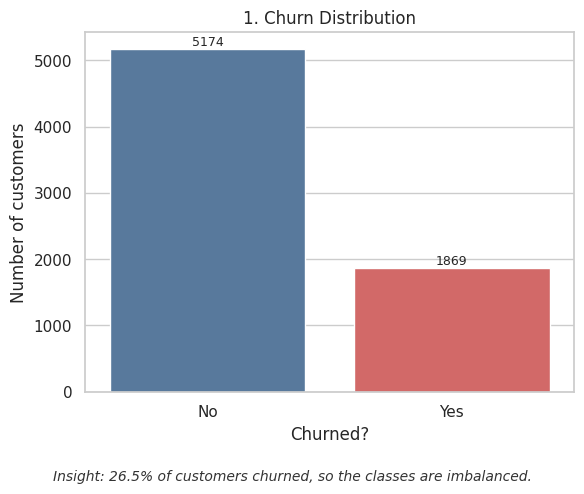

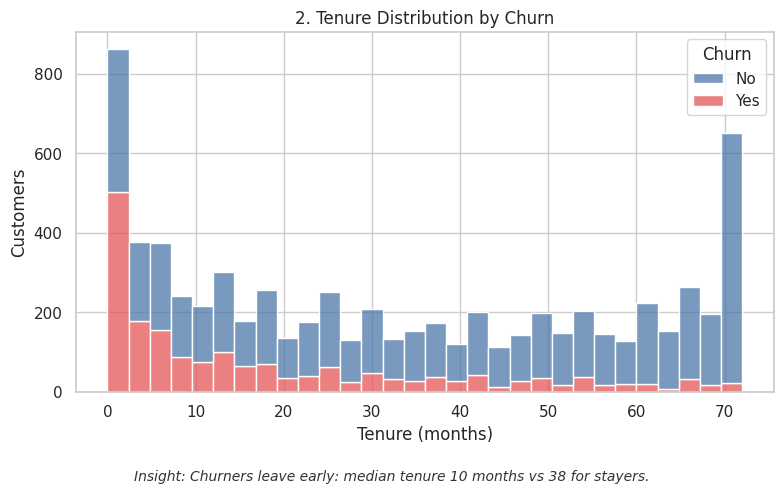

/tmp/ipykernel_1176/1999742205.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", order=HUE_ORDER, palette=PALETTE, ax=ax)


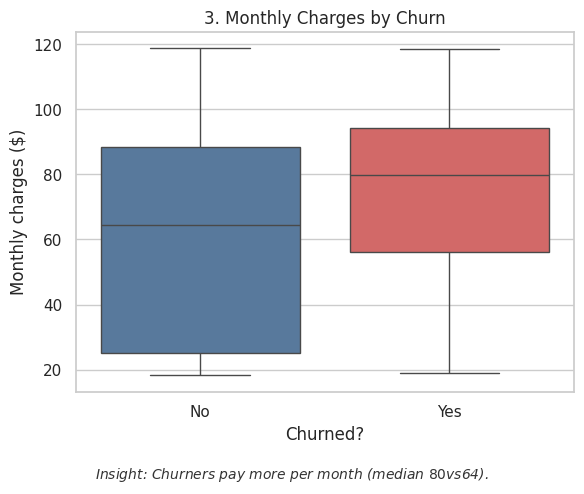

/tmp/ipykernel_1176/1999742205.py:93: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="TotalCharges", order=HUE_ORDER, palette=PALETTE, ax=ax)


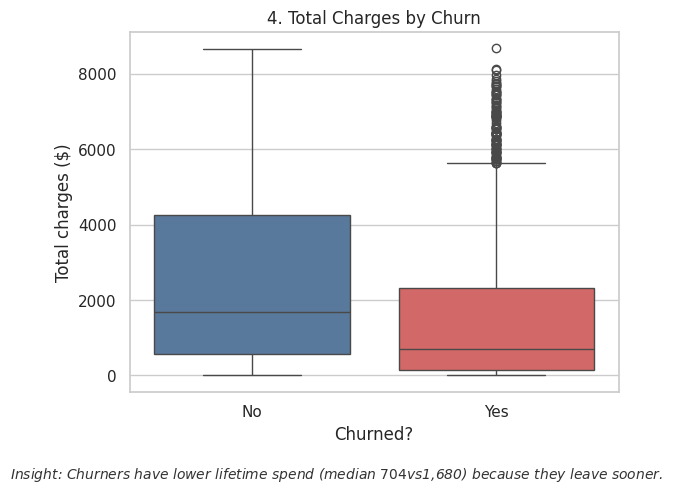

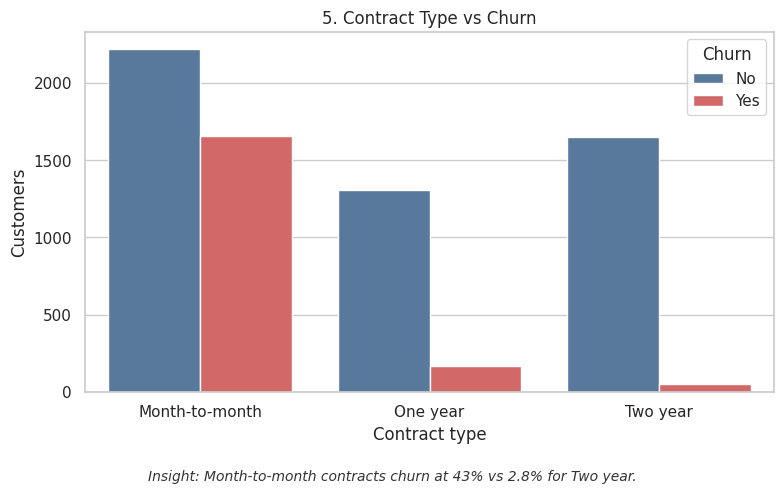

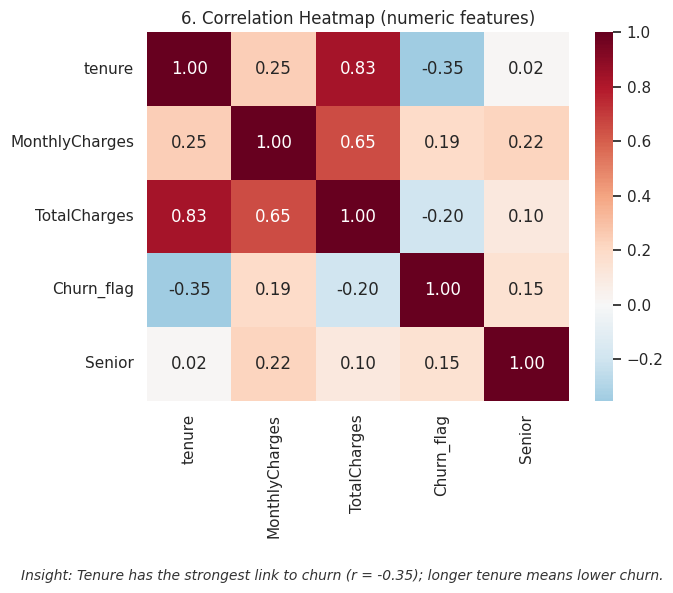

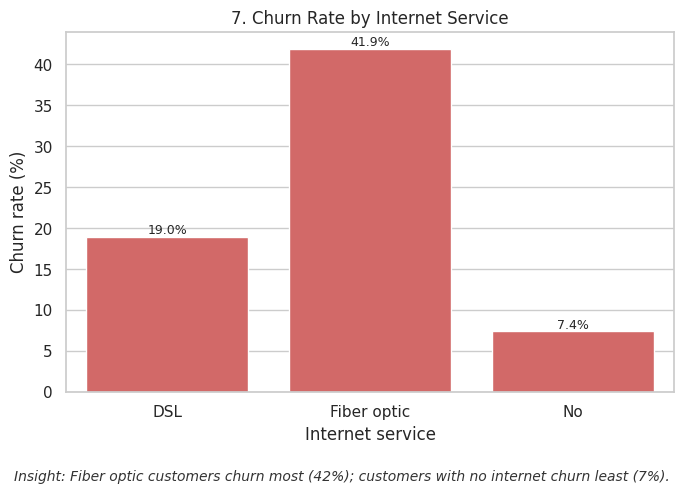

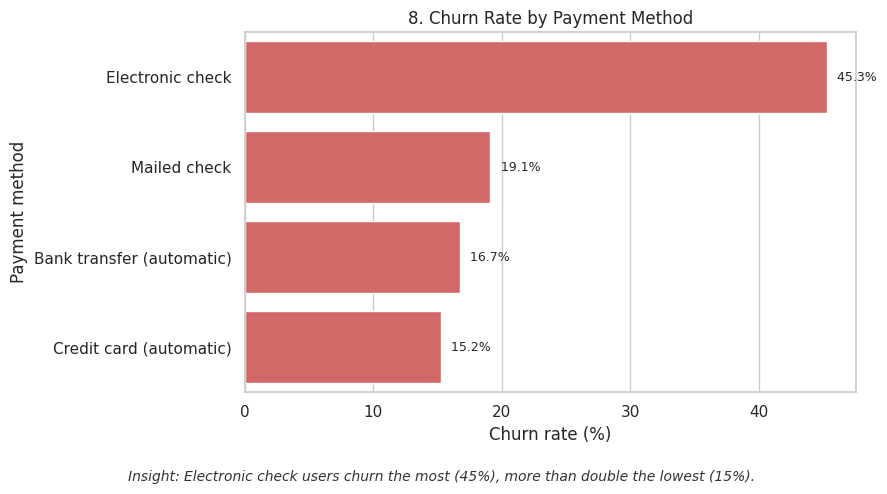

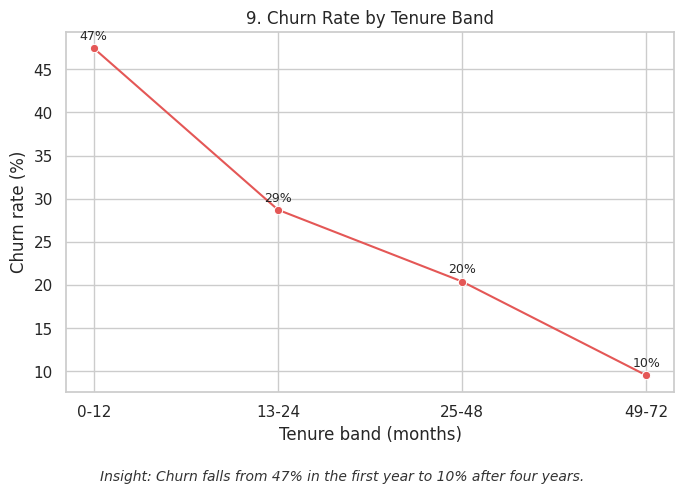

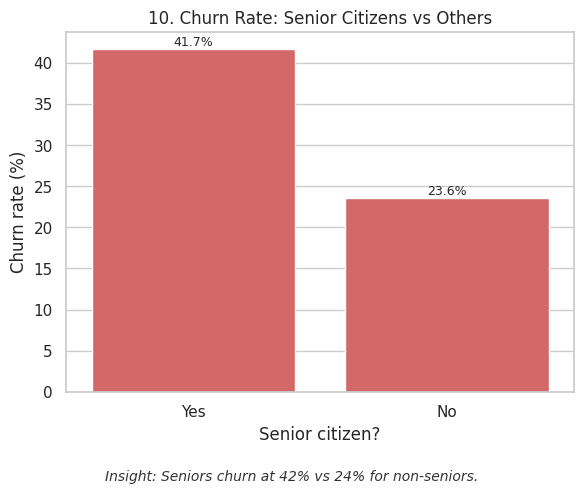

In [ ]:
"""Module 4: Data Visualization - tell the churn story with 12 charts.

Expects the cleaned DataFrame from telco_cleaning.clean_telco()
(needs columns: Churn, Churn_flag, tenure, MonthlyCharges, TotalCharges, ...).

Usage in Colab:
    from telco_cleaning import load_data, clean_telco
    from telco_viz import plot_all
    df = clean_telco(load_data("/content/churn.csv"))
    plot_all(df, save_dir="charts")
"""
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

PALETTE = {"No": "#4C78A8", "Yes": "#E45756"}
HUE_ORDER = ["No", "Yes"]
sns.set_theme(style="whitegrid", context="notebook")


# ---------- helpers ----------
def _finish(fig, insight, name, save_dir=None):
    """Add a one-line insight below a matplotlib chart, save and show it."""
    fig.tight_layout(rect=[0, 0.06, 1, 1])
    fig.text(0.5, 0.015, f"Insight: {insight}", ha="center", va="bottom",
             fontsize=10, style="italic", color="#333333")
    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
        fig.savefig(os.path.join(save_dir, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()


def _finish_plotly(fig, insight, name, save_dir=None):
    """Add a one-line insight below a Plotly chart, save HTML and show it."""
    fig.add_annotation(text=f"<i>Insight: {insight}</i>", xref="paper", yref="paper",
                       x=0.5, y=-0.22, showarrow=False, font=dict(size=12))
    fig.update_layout(margin=dict(b=110), template="plotly_white")
    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
        fig.write_html(os.path.join(save_dir, f"{name}.html"))
    fig.show()


def _label_bars(ax, fmt="{:.0f}", suffix=""):
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(fmt.format(h) + suffix, (p.get_x() + p.get_width() / 2, h),
                        ha="center", va="bottom", fontsize=9)


def _rate(df, col):
    """Churn rate (%) by a categorical column, sorted high to low."""
    return (df.groupby(col, observed=True)["Churn_flag"].mean() * 100).sort_values(ascending=False)


# ---------- static charts (matplotlib / seaborn) ----------
def chart_churn_distribution(df, save_dir=None):
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.countplot(data=df, x="Churn", order=HUE_ORDER, palette=PALETTE, ax=ax)
    _label_bars(ax)
    ax.set(title="1. Churn Distribution", xlabel="Churned?", ylabel="Number of customers")
    pct = df["Churn_flag"].mean() * 100
    _finish(fig, f"{pct:.1f}% of customers churned, so the classes are imbalanced.",
            "01_churn_distribution", save_dir)


def chart_tenure_hist(df, save_dir=None):
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.histplot(data=df, x="tenure", hue="Churn", hue_order=HUE_ORDER, palette=PALETTE,
                 multiple="stack", bins=30, ax=ax)
    ax.set(title="2. Tenure Distribution by Churn", xlabel="Tenure (months)", ylabel="Customers")
    med = df.groupby("Churn", observed=True)["tenure"].median()
    _finish(fig, f"Churners leave early: median tenure {med['Yes']:.0f} months vs {med['No']:.0f} for stayers.",
            "02_tenure_hist", save_dir)


def chart_box_monthly(df, save_dir=None):
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.boxplot(data=df, x="Churn", y="MonthlyCharges", order=HUE_ORDER, palette=PALETTE, ax=ax)
    ax.set(title="3. Monthly Charges by Churn", xlabel="Churned?", ylabel="Monthly charges ($)")
    med = df.groupby("Churn", observed=True)["MonthlyCharges"].median()
    _finish(fig, f"Churners pay more per month (median ${med['Yes']:.0f} vs ${med['No']:.0f}).",
            "03_box_monthly", save_dir)


def chart_box_total(df, save_dir=None):
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.boxplot(data=df, x="Churn", y="TotalCharges", order=HUE_ORDER, palette=PALETTE, ax=ax)
    ax.set(title="4. Total Charges by Churn", xlabel="Churned?", ylabel="Total charges ($)")
    med = df.groupby("Churn", observed=True)["TotalCharges"].median()
    _finish(fig, f"Churners have lower lifetime spend (median ${med['Yes']:,.0f} vs ${med['No']:,.0f}) because they leave sooner.",
            "04_box_total", save_dir)


def chart_contract_churn(df, save_dir=None):
    fig, ax = plt.subplots(figsize=(8, 5))
    order = ["Month-to-month", "One year", "Two year"]
    sns.countplot(data=df, x="Contract", hue="Churn", order=order, hue_order=HUE_ORDER,
                  palette=PALETTE, ax=ax)
    ax.set(title="5. Contract Type vs Churn", xlabel="Contract type", ylabel="Customers")
    r = _rate(df, "Contract")
    _finish(fig, f"{r.index[0]} contracts churn at {r.iloc[0]:.0f}% vs {r.iloc[-1]:.1f}% for {r.index[-1]}.",
            "05_contract_churn", save_dir)


def chart_corr_heatmap(df, save_dir=None):
    num = df[["tenure", "MonthlyCharges", "TotalCharges", "Churn_flag"]].copy()
    num["Senior"] = (df["SeniorCitizen"].astype(str) == "Yes").astype(int)
    corr = num.corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
    ax.set_title("6. Correlation Heatmap (numeric features)")
    t = corr.loc["tenure", "Churn_flag"]
    _finish(fig, f"Tenure has the strongest link to churn (r = {t:.2f}); longer tenure means lower churn.",
            "06_corr_heatmap", save_dir)


def chart_internet_churn(df, save_dir=None):
    r = _rate(df, "InternetService")
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.barplot(x=r.index, y=r.values, color="#E45756", ax=ax)
    _label_bars(ax, "{:.1f}", "%")
    ax.set(title="7. Churn Rate by Internet Service", xlabel="Internet service", ylabel="Churn rate (%)")
    _finish(fig, f"{r.index[0]} customers churn most ({r.iloc[0]:.0f}%); customers with no internet churn least ({r.iloc[-1]:.0f}%).",
            "07_internet_churn", save_dir)


def chart_payment_churn(df, save_dir=None):
    r = _rate(df, "PaymentMethod")
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(x=r.values, y=r.index.astype(str), color="#E45756", ax=ax)
    for i, v in enumerate(r.values):
        ax.text(v + 0.5, i, f" {v:.1f}%", va="center", fontsize=9)
    ax.set(title="8. Churn Rate by Payment Method", xlabel="Churn rate (%)", ylabel="Payment method")
    _finish(fig, f"{r.index[0]} users churn the most ({r.iloc[0]:.0f}%), more than double the lowest ({r.iloc[-1]:.0f}%).",
            "08_payment_churn", save_dir)


def chart_tenure_band(df, save_dir=None):
    bands = pd.cut(df["tenure"], [-1, 12, 24, 48, 72],
                   labels=["0-12", "13-24", "25-48", "49-72"])
    r = df.groupby(bands, observed=True)["Churn_flag"].mean() * 100
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.lineplot(x=r.index.astype(str), y=r.values, marker="o", color="#E45756", ax=ax)
    for i, v in enumerate(r.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set(title="9. Churn Rate by Tenure Band", xlabel="Tenure band (months)", ylabel="Churn rate (%)")
    _finish(fig, f"Churn falls from {r.iloc[0]:.0f}% in the first year to {r.iloc[-1]:.0f}% after four years.",
            "09_tenure_band", save_dir)


def chart_senior_churn(df, save_dir=None):
    r = _rate(df, "SeniorCitizen")
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.barplot(x=r.index.astype(str), y=r.values, color="#E45756", ax=ax)
    _label_bars(ax, "{:.1f}", "%")
    ax.set(title="10. Churn Rate: Senior Citizens vs Others", xlabel="Senior citizen?", ylabel="Churn rate (%)")
    _finish(fig, f"Seniors churn at {r.get('Yes', np.nan):.0f}% vs {r.get('No', np.nan):.0f}% for non-seniors.",
            "10_senior_churn", save_dir)


# ---------- interactive charts (Plotly) ----------
def chart_plotly_scatter(df, save_dir=None):
    d = df.assign(Churn=df["Churn"].astype(str))
    fig = px.scatter(d, x="tenure", y="MonthlyCharges", color="Churn",
                     color_discrete_map=PALETTE, opacity=0.5,
                     hover_data=["Contract", "InternetService", "TotalCharges"],
                     title="11. Tenure vs Monthly Charges (interactive)",
                     labels={"tenure": "Tenure (months)", "MonthlyCharges": "Monthly charges ($)"})
    _finish_plotly(fig, "Churners cluster at short tenure and higher monthly charges; hover to inspect customers.",
                   "11_plotly_scatter", save_dir)


def chart_plotly_heatmap(df, save_dir=None):
    pv = df.pivot_table(index="Contract", columns="InternetService", values="Churn_flag",
                        aggfunc="mean", observed=True) * 100
    fig = px.imshow(pv.round(1), text_auto=True, color_continuous_scale="Reds", aspect="auto",
                    title="12. Churn Rate (%) by Contract and Internet Service (interactive)",
                    labels=dict(x="Internet service", y="Contract", color="Churn %"))
    stacked = pv.stack()
    worst = stacked.idxmax()
    _finish_plotly(fig, f"Highest risk: {worst[0]} + {worst[1]} at {stacked.max():.0f}% churn; two-year contracts stay low.",
                   "12_plotly_heatmap", save_dir)


# ---------- run everything ----------
def plot_all(df, save_dir=None):
    for fn in (chart_churn_distribution, chart_tenure_hist, chart_box_monthly,
               chart_box_total, chart_contract_churn, chart_corr_heatmap,
               chart_internet_churn, chart_payment_churn, chart_tenure_band,
               chart_senior_churn, chart_plotly_scatter, chart_plotly_heatmap):
        fn(df, save_dir)


if __name__ == "__main__":
    # Use the active cleaned DataFrame 'clean' already loaded in Colab
    if 'clean' in globals():
        plot_all(clean, save_dir="charts")
    else:
        print("Cleaned DataFrame 'clean' not found in memory. Please run cell -lv2QeQOPbZf first.")

In [ ]:
"""Module 5: score every customer and export churn_scored.csv for Power BI / Tableau.

Expects ChurnPipeline and the cleaned DataFrame 'clean' to be already loaded in memory.

Usage in Colab:
    scored = score_and_export(clean)          # saves + downloads churn_scored.csv
"""
import logging

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Note: We rely on ChurnPipeline being defined in cell 0eyRy9b2Oy-U in the global namespace

logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s | %(levelname)s | %(message)s", force=True)
logger = logging.getLogger(__name__)

MEDIUM_RISK = 0.30   # churn_prob above this = Medium
HIGH_RISK = 0.60     # churn_prob above this = High


def score_customers(df: pd.DataFrame) -> pd.DataFrame:
    """Add churn_prob, risk_band, is_active and revenue_at_risk columns.

    Probabilities are out-of-fold (5-fold CV), so every customer is scored by a
    model that never saw that customer. Scoring the training rows directly would
    give overconfident probabilities (a random forest memorises its training data).
    """
    X = df.drop(columns=["customerID", "Churn", "Churn_flag"])
    X = X.astype({c: "object" for c in X.select_dtypes("category").columns})
    y = df["Churn_flag"]

    # Use the globally available ChurnPipeline class
    model = ChurnPipeline()._build_model(X)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    proba = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]

    out = df.copy()
    out["churn_prob"] = proba.round(4)
    out["risk_band"] = pd.cut(out["churn_prob"], [-0.01, MEDIUM_RISK, HIGH_RISK, 1.0],
                              labels=["Low", "Medium", "High"]).astype(str)
    out["is_active"] = (out["Churn"].astype(str) == "No").astype(int)

    # Monthly revenue from active customers we are likely to lose
    at_risk = (out["is_active" ] == 1) & (out["churn_prob"] > HIGH_RISK)
    out["revenue_at_risk"] = np.where(at_risk, out["MonthlyCharges"], 0.0)
    return out


def score_and_export(df: pd.DataFrame, path: str = "churn_scored.csv") -> pd.DataFrame:
    scored = score_customers(df)
    scored.to_csv(path, index=False)
    logger.info("Saved %s rows x %s cols to %s", *scored.shape, path)

    # Numbers to compare against your dashboard KPIs
    logger.info("Churn %%: %.1f", scored["Churn_flag"].mean() * 100)
    logger.info("Avg tenure: %.1f months", scored["tenure"].mean())
    logger.info("Revenue at risk: $%s / month (%s customers)",
                f"{scored['revenue_at_risk'].sum():,.0f}", int((scored["revenue_at_risk"] > 0).sum()))

    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        logger.info("Not running in Colab - file saved locally only")
    return scored


if __name__ == "__main__":
    # Check if cleaned DataFrame is available in the global namespace
    if 'clean' in globals():
        score_and_export(clean)
    else:
        logger.error("The active DataFrame 'clean' was not found in memory. Please run cell -lv2QeQOPbZf first.")

2026-10-30 04:08:43,887 | INFO | Saved 7043 rows x 26 cols to churn_scored.csv
2026-10-30 04:08:43,888 | INFO | Churn %: 26.5
2026-10-30 04:08:43,889 | INFO | Avg tenure: 32.4 months
2026-10-30 04:08:43,891 | INFO | Revenue at risk: $24,587 / month (335 customers)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# EDA & Feature Engineering
#
# Create features that improve the model.
#
# • New features: tenure_group, num_services, avg_monthly_spend, has_support_services, is_autopay.
# • Encode: One-Hot (nominal), Ordinal (Contract). Scale: StandardScaler.
# • Handle imbalance (~26% churn) with class_weight or SMOTE (apply only on training data).
# • Put everything in a ColumnTransformer + Pipeline to avoid data leakage.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import pandas as pd

# Identify columns dynamically using the active cleaned DataFrame in memory
if 'clean' in globals():
    num_cols = clean.select_dtypes(include=['number']).columns.tolist()
    if 'Churn_flag' in num_cols:
        num_cols.remove('Churn_flag')

    cat_cols = clean.select_dtypes(exclude=['number']).columns.tolist()
    if 'customerID' in cat_cols:
        cat_cols.remove('customerID')
    if 'Churn' in cat_cols:
        cat_cols.remove('Churn')
else:
    # Fallback default values
    num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
    cat_cols = ['gender', 'Partner', 'Dependents', 'Contract', 'InternetService', 'PaymentMethod']

# Construct the ColumnTransformer pipeline cleanly
pre = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

print("ColumnTransformer constructed successfully!")

ColumnTransformer constructed successfully!


2026-10-30 04:08:44,010 | INFO | Train: 5634 rows | Test: 1409 rows | churn rate train/test: 26.5% / 26.5%
2026-10-30 04:08:44,648 | INFO | Logistic Regression  F1=0.616  AUC=0.842  (0.3s)
2026-10-30 04:08:45,063 | INFO | KNN                  F1=0.568  AUC=0.821  (0.1s)
2026-10-30 04:08:45,231 | INFO | Naive Bayes          F1=0.607  AUC=0.821  (0.1s)
2026-10-30 04:08:45,442 | INFO | Decision Tree        F1=0.632  AUC=0.835  (0.1s)
2026-10-30 04:08:48,375 | INFO | Random Forest        F1=0.620  AUC=0.840  (2.7s)
2026-10-30 04:08:50,621 | INFO | SVM (RBF)            F1=0.617  AUC=0.823  (1.5s)
2026-10-30 04:08:51,065 | INFO | XGBoost              F1=0.621  AUC=0.838  (0.4s)


                 model  accuracy  precision  recall     f1  roc_auc  \
0  Logistic Regression     0.740      0.507   0.786  0.616    0.842   
1        Random Forest     0.779      0.569   0.682  0.620    0.840   
2              XGBoost     0.747      0.516   0.781  0.621    0.838   
3        Decision Tree     0.756      0.527   0.791  0.632    0.835   
4            SVM (RBF)     0.745      0.513   0.773  0.617    0.823   
5          Naive Bayes     0.744      0.513   0.743  0.607    0.821   
6                  KNN     0.778      0.587   0.551  0.568    0.821   

   train_seconds  
0          0.271  
1          2.688  
2          0.379  
3          0.136  
4          1.547  
5          0.094  
6          0.098  


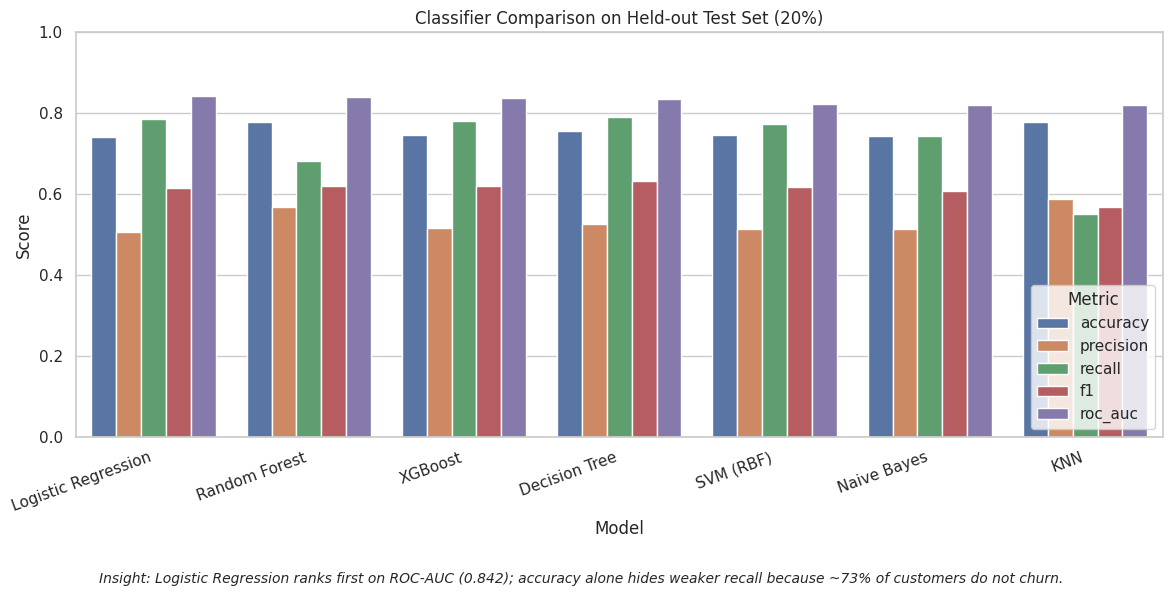

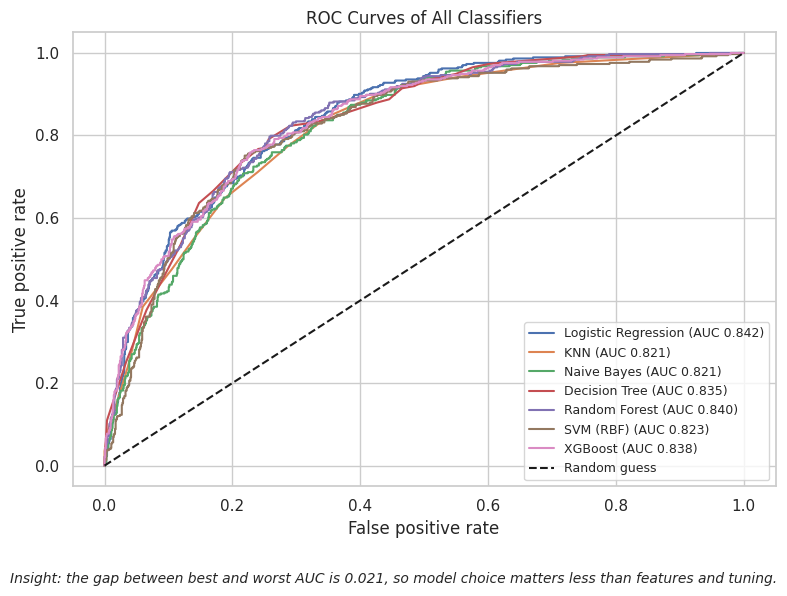

In [ ]:
"""Module 8: Supervised ML - train and compare 7 classifiers on Telco churn.

Needs the cleaned DataFrame from telco_cleaning.clean_telco().

Usage in Colab:
    from telco_cleaning import load_data, clean_telco
    from model_comparison import compare_models, plot_comparison, plot_roc
    df = clean_telco(load_data("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"))
    results, fitted, X_test, y_test = compare_models(df)
    results
    plot_comparison(results)
    plot_roc(fitted, X_test, y_test)
"""
import logging
import time

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s | %(levelname)s | %(message)s", force=True)
logger = logging.getLogger(__name__)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42


# ---------- data prep ----------
def prepare_xy(df: pd.DataFrame):
    X = df.drop(columns=["customerID", "Churn", "Churn_flag"])
    X = X.astype({c: "object" for c in X.select_dtypes("category").columns})
    return X, df["Churn_flag"]


def build_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    """Impute + scale numeric, impute + one-hot categorical (dense output for Naive Bayes)."""
    num = X.select_dtypes(include="number").columns.tolist()
    cat = X.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
    ])


def get_models(pos_weight: float) -> dict:
    """The classifiers to compare. Class weights handle the ~27% churn imbalance."""
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
        "KNN": KNeighborsClassifier(n_neighbors=15),
        "Naive Bayes": GaussianNB(),
        "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                class_weight="balanced_subsample",
                                                random_state=SEED, n_jobs=-1),
        "SVM (RBF)": SVC(kernel="rbf", class_weight="balanced", random_state=SEED),
    }
    try:
        from xgboost import XGBClassifier
        models["XGBoost"] = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                          scale_pos_weight=pos_weight, eval_metric="logloss",
                                          random_state=SEED)
    except ImportError:
        try:
            from lightgbm import LGBMClassifier
            models["LightGBM"] = LGBMClassifier(n_estimators=300, learning_rate=0.05,
                                                class_weight="balanced", random_state=SEED,
                                                verbose=-1)
        except ImportError:
            logger.warning("Neither xgboost nor lightgbm is installed - skipping boosted model")
    return models


def _scores(model, X):
    """Probability of churn, or the SVM decision score when probabilities are unavailable."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


# ---------- training and comparison ----------
def compare_models(df: pd.DataFrame, test_size: float = 0.2):
    X, y = prepare_xy(df)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=SEED)
    logger.info("Train: %s rows | Test: %s rows | churn rate train/test: %.1f%% / %.1f%%",
                len(X_train), len(X_test), y_train.mean() * 100, y_test.mean() * 100)

    pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
    rows, fitted = [], {}
    for name, clf in get_models(pos_weight).items():
        try:
            pipe = Pipeline([("prep", build_preprocessor(X_train)), ("clf", clf)])
            t0 = time.time()
            pipe.fit(X_train, y_train)
            secs = time.time() - t0
            preds = pipe.predict(X_test)
            rows.append({
                "model": name,
                "accuracy": accuracy_score(y_test, preds),
                "precision": precision_score(y_test, preds, zero_division=0),
                "recall": recall_score(y_test, preds),
                "f1": f1_score(y_test, preds),
                "roc_auc": roc_auc_score(y_test, _scores(pipe, X_test)),
                "train_seconds": secs,
            })
            fitted[name] = pipe
            logger.info("%-20s F1=%.3f  AUC=%.3f  (%.1fs)", name,
                        rows[-1]["f1"], rows[-1]["roc_auc"], secs)
        except Exception as e:  # keep going if one model fails
            logger.error("%s failed: %s", name, e)

    results = (pd.DataFrame(rows).sort_values("roc_auc", ascending=False)
               .reset_index(drop=True).round(3))
    return results, fitted, X_test, y_test


# ---------- plots ----------
def plot_comparison(results: pd.DataFrame, save_path: str = None):
    metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
    long = results.melt(id_vars="model", value_vars=metrics, var_name="metric", value_name="score")
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.barplot(data=long, x="model", y="score", hue="metric", order=results["model"], ax=ax)
    ax.set(title="Classifier Comparison on Held-out Test Set (20%)",
           xlabel="Model", ylabel="Score", ylim=(0, 1))
    ax.legend(title="Metric", loc="lower right")
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
    best = results.iloc[0]
    fig.tight_layout(rect=[0, 0.06, 1, 1])
    fig.text(0.5, 0.015,
             f"Insight: {best["model"]} ranks first on ROC-AUC ({best["roc_auc"]:.3f}); "
             f"accuracy alone hides weaker recall because ~73% of customers do not churn.",
             ha="center", fontsize=10, style="italic")
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_roc(fitted: dict, X_test, y_test, save_path: str = None):
    fig, ax = plt.subplots(figsize=(8, 6))
    aucs = {}
    for name, pipe in fitted.items():
        s = _scores(pipe, X_test)
        fpr, tpr, _ = roc_curve(y_test, s)
        aucs[name] = roc_auc_score(y_test, s)
        ax.plot(fpr, tpr, label=f"{name} (AUC {aucs[name]:.3f})")
    ax.plot([0, 1], [0, 1], "k--", label="Random guess")
    ax.set(title="ROC Curves of All Classifiers", xlabel="False positive rate",
           ylabel="True positive rate")
    ax.legend(loc="lower right", fontsize=9)
    spread = max(aucs.values()) - min(aucs.values())
    fig.tight_layout(rect=[0, 0.06, 1, 1])
    fig.text(0.5, 0.015,
             f"Insight: the gap between best and worst AUC is {spread:.3f}, "
             f"so model choice matters less than features and tuning.",
             ha="center", fontsize=10, style="italic")
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


if __name__ == "__main__":
    if 'clean' in globals():
        res, fit, Xt, yt = compare_models(clean)
        print(res)
        plot_comparison(res)
        plot_roc(fit, Xt, yt)
    else:
        logger.error("The active DataFrame 'clean' was not found in memory.")

2026-10-30 04:08:52,485 | INFO | Cost assumptions: loss per churner $893 | offer $50 | offer success 50%
2026-10-30 04:09:01,136 | INFO | Logistic Regression  CV PR-AUC=0.661  ROC-AUC=0.846
2026-10-30 04:11:15,937 | INFO | Random Forest        CV PR-AUC=0.665  ROC-AUC=0.847
2026-10-30 04:11:42,314 | INFO | XGBoost              CV PR-AUC=0.670  ROC-AUC=0.849
2026-10-30 04:11:42,320 | INFO | Best model by CV PR-AUC: XGBoost


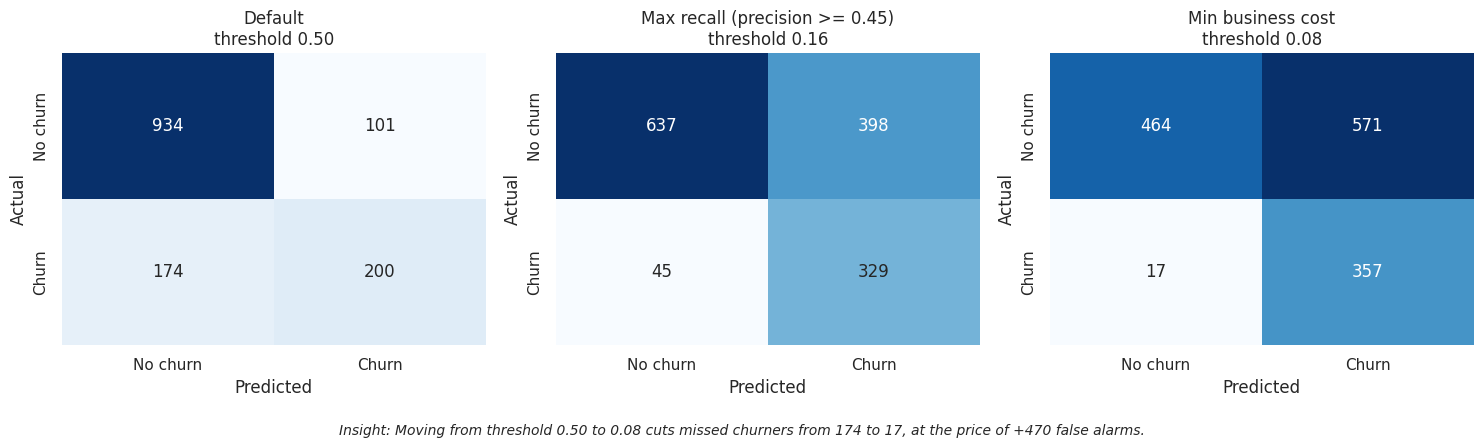

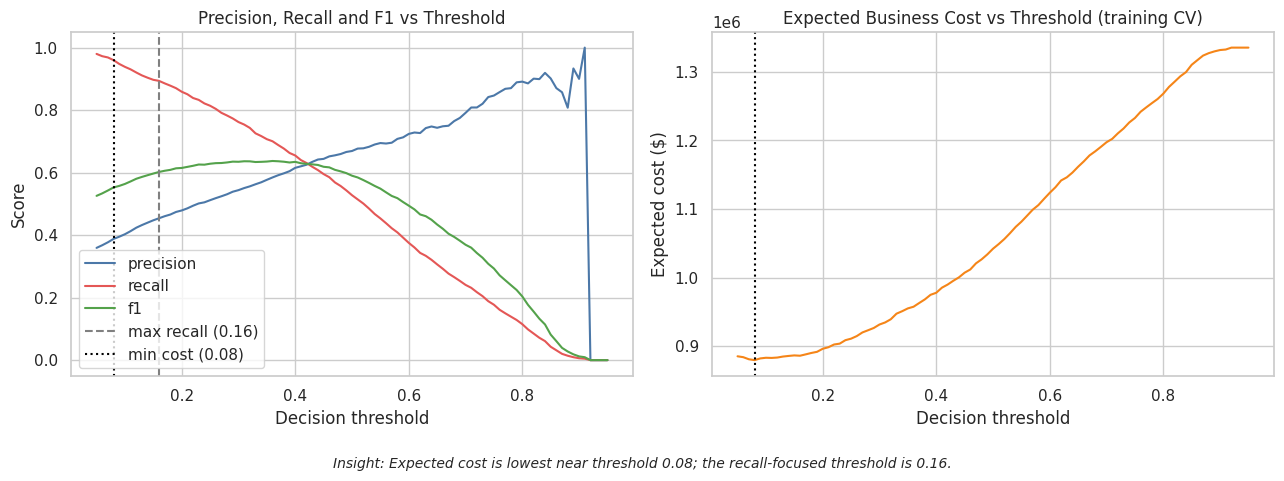

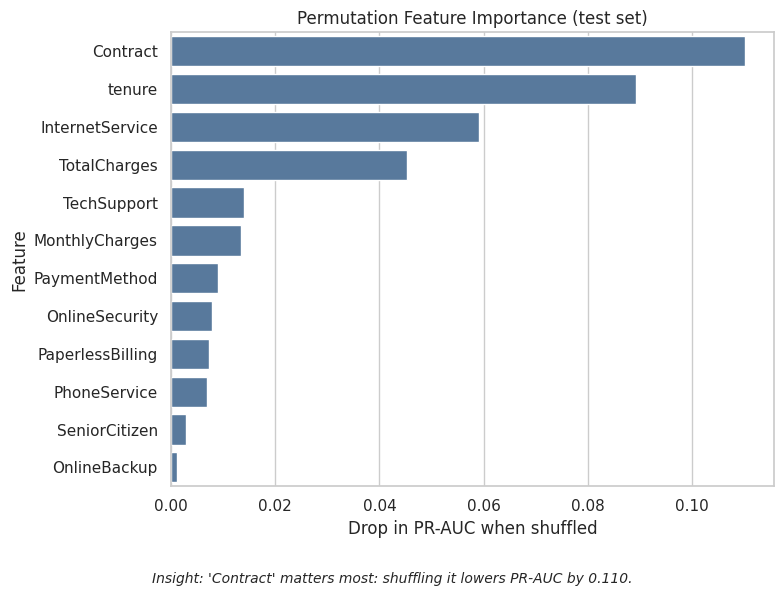

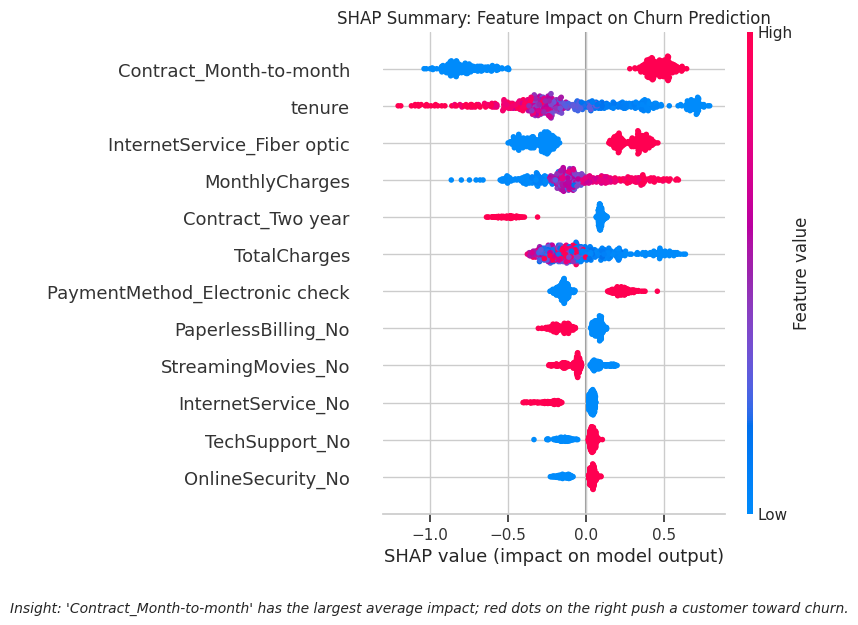

2026-10-30 04:11:51,650 | INFO | Best strategy: Min business cost (threshold 0.08) -> recall 0.95, precision 0.39, saves ~$113,053 on the test set vs doing nothing


                 model  cv_pr_auc  cv_pr_auc_std  cv_roc_auc  cv_recall  cv_f1
0              XGBoost      0.670          0.020       0.849      0.528  0.590
1        Random Forest      0.665          0.018       0.847      0.498  0.573
2  Logistic Regression      0.661          0.019       0.846      0.542  0.592
                         strategy  threshold  precision  recall     f1   tp  \
0                         Default       0.50      0.664   0.535  0.593  200   
1  Max recall (precision >= 0.45)       0.16      0.453   0.880  0.598  329   
2               Min business cost       0.08      0.385   0.955  0.548  357   

    fp   fn   tn  roc_auc  pr_auc  expected_cost  no_model_cost     savings  
0  101  174  934    0.848   0.667     259813.100     334092.699   74279.599  
1  398   45  637    0.848   0.667     223495.509     334092.699  110597.190  
2  571   17  464    0.848   0.667     221039.365     334092.699  113053.334  


In [ ]:
"""Module 9: Evaluation & Tuning - choose the best model for the business.

Needs the cleaned DataFrame from telco_cleaning.clean_telco().
For SHAP, run once in Colab:  !pip install shap

Usage in Colab:
    from telco_cleaning import load_data, clean_telco
    from model_tuning import run_evaluation, CostConfig
    df = clean_telco(load_data("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"))
    out = run_evaluation(df, cfg=CostConfig(months_lost=12, offer_cost=50, offer_success_rate=0.5))
    out["cv_table"]      # cross-validated scores of tuned models
    out["final"]         # test-set metrics + business cost at each threshold
"""
import logging
from dataclasses import dataclass, replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.pipeline import Pipeline

# Note: SEED, build_preprocessor, and prepare_xy are assumed to be loaded globally from cell MZhyfziYROQW
if "SEED" not in globals():
    SEED = 42

logger = logging.getLogger(__name__)
sns.set_theme(style="whitegrid", context="notebook")


# ---------- business assumptions (EDIT THESE and state them in your write-up) ----------
@dataclass
class CostConfig:
    months_lost: int = 12  # months of revenue lost when a customer churns
    offer_cost: float = 50.0  # cost of one retention offer (discount, call, etc.)
    offer_success_rate: float = 0.5  # share of true churners an offer actually saves
    loss_per_churner: float = (
        None  # if None: months_lost x avg monthly charge of churners
    )


def expected_cost(tp, fp, fn, cfg: CostConfig) -> float:
    """Offers go to everyone flagged (TP+FP). Churners we miss (FN) or fail to save are lost."""
    loss = cfg.loss_per_churner
    return (
        (tp + fp) * cfg.offer_cost
        + fn * loss
        + tp * (1 - cfg.offer_success_rate) * loss
    )


def metrics_at(y_true, proba, threshold) -> dict:
    pred = (proba >= threshold).astype(int)
    y = np.asarray(y_true)
    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    return {
        "threshold": round(float(threshold), 2),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
    }


def _footer(fig, insight, name, save_dir):
    fig.tight_layout(rect=[0, 0.06, 1, 1])
    fig.text(
        0.5,
        0.015,
        f"Insight: {insight}",
        ha="center",
        fontsize=10,
        style="italic",
    )
    if save_dir:
        import os

        os.makedirs(save_dir, exist_ok=True)
        fig.savefig(
            os.path.join(save_dir, f"{name}.png"),
            dpi=150,
            bbox_inches="tight",
        )
    plt.show()


# ---------- 1. cross-validated hyperparameter tuning ----------
def tune_models(X_train, y_train, n_iter: int = 12):
    """GridSearchCV (logistic regression) and RandomizedSearchCV (RF, XGBoost) with StratifiedKFold."""
    pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
    spaces = {
        "Logistic Regression": (
            LogisticRegression(max_iter=2000, random_state=SEED),
            {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]},
            "grid",
        ),
        "Random Forest": (
            RandomForestClassifier(random_state=SEED, n_jobs=1),
            {
                "clf__n_estimators": [200, 400],
                "clf__max_depth": [4, 6, 8, None],
                "clf__min_samples_leaf": [1, 3, 5, 10],
                "clf__max_features": ["sqrt", 0.5],
                "clf__class_weight": ["balanced_subsample", None],
            },
            "random",
        ),
    }
    try:
        from xgboost import XGBClassifier

        spaces["XGBoost"] = (
            XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1),
            {
                "clf__n_estimators": [200, 400, 600],
                "clf__max_depth": [3, 4, 5],
                "clf__learning_rate": [0.01, 0.03, 0.05, 0.1],
                "clf__subsample": [0.7, 0.85, 1.0],
                "clf__colsample_bytree": [0.7, 0.85, 1.0],
                "clf__scale_pos_weight": [1.0, pos_weight],
            },
            "random",
        )
    except ImportError:
        logger.warning("xgboost not installed - skipping it")

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    scoring = {
        "pr_auc": "average_precision",
        "roc_auc": "roc_auc",
        "recall": "recall",
        "f1": "f1",
    }
    rows, best = [], {}
    for name, (est, params, kind) in spaces.items():
        pipe = Pipeline([("prep", build_preprocessor(X_train)), ("clf", est)])
        if kind == "grid":
            search = GridSearchCV(
                pipe,
                params,
                scoring=scoring,
                refit="pr_auc",
                cv=skf,
                n_jobs=-1,
            )
        else:
            search = RandomizedSearchCV(
                pipe,
                params,
                n_iter=n_iter,
                scoring=scoring,
                refit="pr_auc",
                cv=skf,
                n_jobs=-1,
                random_state=SEED,
            )
        try:
            search.fit(X_train, y_train)
        except Exception as e:
            logger.error("%s tuning failed: %s", name, e)
            continue
        i, r = search.best_index_, search.cv_results_
        rows.append({
            "model": name,
            "cv_pr_auc": r["mean_test_pr_auc"][i],
            "cv_pr_auc_std": r["std_test_pr_auc"][i],
            "cv_roc_auc": r["mean_test_roc_auc"][i],
            "cv_recall": r["mean_test_recall"][i],
            "cv_f1": r["mean_test_f1"][i],
            "best_params": {
                k.replace("clf__", ""): v for k, v in search.best_params_.items()
            },
        })
        best[name] = search.best_estimator_
        logger.info(
            "%-20s CV PR-AUC=%.3f  ROC-AUC=%.3f",
            name,
            rows[-1]["cv_pr_auc"],
            rows[-1]["cv_roc_auc"],
        )
    table = (
        pd.DataFrame(rows)
        .sort_values("cv_pr_auc", ascending=False)
        .reset_index(drop=True)
    )
    num = table.select_dtypes("number").columns
    table[num] = table[num].round(3)
    return table, best


# ---------- 2. threshold tuning ----------
def choose_thresholds(y_true, proba, cfg: CostConfig, min_precision: float = 0.45):
    """Pick thresholds from out-of-fold TRAINING predictions (never from the test set)."""
    curve = pd.DataFrame([
        {**metrics_at(y_true, proba, t)}
        for t in np.arange(0.05, 0.96, 0.01)
    ])
    curve["cost"] = [
        expected_cost(r.tp, r.fp, r.fn, cfg) for r in curve.itertuples()
    ]
    ok = curve[curve["precision"] >= min_precision]
    t_recall = (
        float(ok.loc[ok["recall"].idxmax(), "threshold"]) if len(ok) else 0.5
    )
    t_cost = float(curve.loc[curve["cost"].idxmin(), "threshold"])
    return t_recall, t_cost, curve


def evaluate_thresholds(
    y_test, proba_test, thresholds: dict, cfg: CostConfig
) -> pd.DataFrame:
    roc, pr = roc_auc_score(y_test, proba_test), average_precision_score(
        y_test, proba_test
    )
    rows = []
    for label, t in thresholds.items():
        m = metrics_at(y_test, proba_test, t)
        cost = expected_cost(m["tp"], m["fp"], m["fn"], cfg)
        baseline = (
            m["tp"] + m["fn"]
        ) * cfg.loss_per_churner  # do nothing: every churner is lost
        rows.append({
            "strategy": label,
            **m,
            "roc_auc": roc,
            "pr_auc": pr,
            "expected_cost": cost,
            "no_model_cost": baseline,
            "savings": baseline - cost,
        })
    out = pd.DataFrame(rows)
    num = out.select_dtypes("number").columns.drop(["tp", "fp", "fn", "tn"])
    out[num] = out[num].round(3)
    return out


# ---------- 3. plots ----------
def plot_confusion_matrices(final: pd.DataFrame, save_dir=None):
    fig, axes = plt.subplots(1, len(final), figsize=(5 * len(final), 4.5))
    for ax, r in zip(np.atleast_1d(axes), final.itertuples()):
        cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            ax=ax,
            xticklabels=["No churn", "Churn"],
            yticklabels=["No churn", "Churn"],
        )
        ax.set(
            title=f"{r.strategy}\nthreshold {r.threshold:.2f}",
            xlabel="Predicted",
            ylabel="Actual",
        )
    a, b = final.iloc[0], final.iloc[-1]
    _footer(
        fig,
        f"Moving from threshold {a.threshold:.2f} to {b.threshold:.2f} cuts missed churners "
        f"from {a.fn} to {b.fn}, at the price of {b.fp - a.fp:+d} false alarms.",
        "confusion_matrices",
        save_dir,
    )


def plot_threshold_curves(curve, t_recall, t_cost, save_dir=None):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    for col, c in [
        ("precision", "#4C78A8"),
        ("recall", "#E45756"),
        ("f1", "#54A24B"),
    ]:
        ax1.plot(curve["threshold"], curve[col], label=col, color=c)
    ax1.axvline(t_recall, ls="--", color="grey", label=f"max recall ({t_recall:.2f})")
    ax1.axvline(t_cost, ls=":", color="black", label=f"min cost ({t_cost:.2f})")
    ax1.set(
        title="Precision, Recall and F1 vs Threshold",
        xlabel="Decision threshold",
        ylabel="Score",
    )
    ax1.legend()
    ax2.plot(curve["threshold"], curve["cost"], color="#F58518")
    ax2.axvline(t_cost, ls=":", color="black")
    ax2.set(
        title="Expected Business Cost vs Threshold (training CV)",
        xlabel="Decision threshold",
        ylabel="Expected cost ($)",
    )
    _footer(
        fig,
        f"Expected cost is lowest near threshold {t_cost:.2f}; the recall-focused threshold is {t_recall:.2f}.",
        "threshold_curves",
        save_dir,
    )


def plot_permutation_importance(
    pipe, X_test, y_test, top: int = 12, save_dir=None
):
    res = permutation_importance(
        pipe,
        X_test,
        y_test,
        scoring="average_precision",
        n_repeats=10,
        random_state=SEED,
        n_jobs=-1,
    )
    imp = pd.Series(res.importances_mean, index=X_test.columns).sort_values(
        ascending=False
    ).head(top)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.barplot(x=imp.values, y=imp.index, color="#4C78A8", ax=ax)
    ax.set(
        title="Permutation Feature Importance (test set)",
        xlabel="Drop in PR-AUC when shuffled",
        ylabel="Feature",
    )
    _footer(
        fig,
        f"'{imp.index[0]}' matters most: shuffling it lowers PR-AUC by {imp.iloc[0]:.3f}.",
        "permutation_importance",
        save_dir,
    )
    return imp


def plot_shap(pipe, X_test, max_samples: int = 500, save_dir=None):
    try:
        import shap
    except ImportError:
        logger.warning("SHAP not installed. In Colab run: !pip install shap")
        return
    prep, clf = pipe.named_steps["prep"], pipe.named_steps["clf"]
    if not hasattr(clf, "feature_importances_"):
        logger.warning(
            "SHAP section expects a tree model (Random Forest / XGBoost); skipping"
        )
        return
    try:
        sample = X_test.sample(min(len(X_test), max_samples), random_state=SEED)
        Xt = prep.transform(sample)
        names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
        sv = shap.TreeExplainer(clf).shap_values(Xt)
        if isinstance(sv, list):
            sv = sv[1]
        elif getattr(sv, "ndim", 2) == 3:
            sv = sv[:, :, 1]
        plt.figure(figsize=(9, 6))
        shap.summary_plot(
            sv, Xt, feature_names=names, max_display=12, show=False
        )
        fig = plt.gcf()
        plt.title("SHAP Summary: Feature Impact on Churn Prediction")
        top = names[int(np.argmax(np.abs(sv).mean(axis=0)))]
        _footer(
            fig,
            f"'{top}' has the largest average impact; red dots on the right push a customer toward churn.",
            "shap_summary",
            save_dir,
        )
    except Exception as e:
        logger.error("SHAP failed (try: !pip install -U shap): %s", e)


# ---------- run everything ----------
def run_evaluation(
    df,
    cfg: CostConfig = None,
    n_iter: int = 12,
    min_precision: float = 0.45,
    save_dir: str = None,
) -> dict:
    cfg = cfg or CostConfig()
    X, y = prepare_xy(df)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=SEED
    )
    if cfg.loss_per_churner is None:
        avg = df.loc[df["Churn_flag"] == 1, "MonthlyCharges"].mean()
        cfg = replace(cfg, loss_per_churner=cfg.months_lost * avg)
    logger.info(
        "Cost assumptions: loss per churner $%.0f | offer $%.0f | offer success %.0f%%",
        cfg.loss_per_churner,
        cfg.offer_cost,
        cfg.offer_success_rate * 100,
    )

    cv_table, best = tune_models(X_train, y_train, n_iter)
    top_name = cv_table.loc[0, "model"]
    pipe = best[top_name]
    logger.info("Best model by CV PR-AUC: %s", top_name)

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof = cross_val_predict(
        pipe, X_train, y_train, cv=skf, method="predict_proba", n_jobs=-1
    )[:, 1]
    t_recall, t_cost, curve = choose_thresholds(
        y_train, oof, cfg, min_precision
    )

    proba_test = pipe.predict_proba(X_test)[:, 1]
    final = evaluate_thresholds(
        y_test,
        proba_test,
        {
            "Default": 0.50,
            f"Max recall (precision >= {min_precision:.2f})": t_recall,
            "Min business cost": t_cost,
        },
        cfg,
    )

    plot_confusion_matrices(final, save_dir)
    plot_threshold_curves(curve, t_recall, t_cost, save_dir)
    plot_permutation_importance(pipe, X_test, y_test, save_dir=save_dir)

    trees = cv_table[cv_table["model"].isin(["Random Forest", "XGBoost"])]
    if len(trees):
        plot_shap(best[trees.iloc[0]["model"]], X_test, save_dir=save_dir)

    b = final.loc[final["savings"].idxmax()]
    logger.info(
        "Best strategy: %s (threshold %.2f) -> recall %.2f, precision %.2f, "
        "saves ~$%s on the test set vs doing nothing",
        b["strategy"],
        b["threshold"],
        b["recall"],
        b["precision"],
        f"{b['savings']:,.0f}",
    )
    return {
        "cv_table": cv_table,
        "final": final,
        "curve": curve,
        "best_name": top_name,
        "best_pipe": pipe,
        "cfg": cfg,
        "thresholds": {"max_recall": t_recall, "min_cost": t_cost},
    }


if __name__ == "__main__":
    logging.basicConfig(
        level=logging.INFO,
        format="%(asctime)s | %(levelname)s | %(message)s",
        force=True,
    )
    if "clean" in globals():
        result = run_evaluation(clean)
        print(result["cv_table"].drop(columns="best_params"))
        print(result["final"])
    else:
        logger.error("The active DataFrame 'clean' was not found in memory.")


2026-10-30 04:11:56,248 | INFO | Class weights: {0: 0.68, 1: 1.88}
2026-10-30 04:12:03,487 | INFO | ANN trained for 15 epochs in 7.1s
2026-10-30 04:12:05,777 | INFO | XGBoost used 280 trees in 2.3s


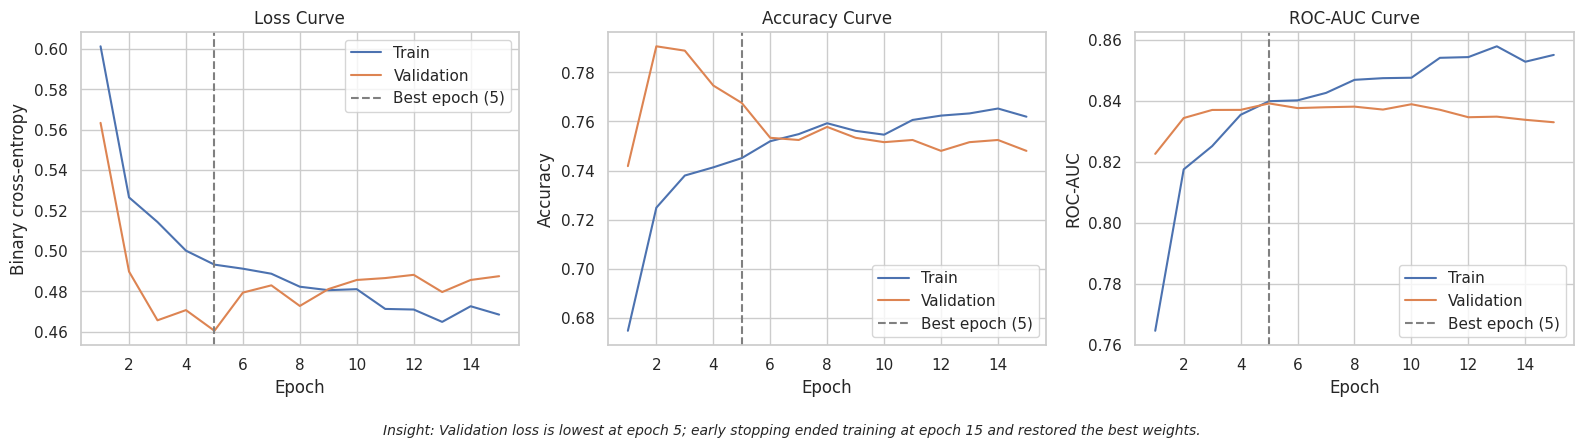

/tmp/ipykernel_1176/1344764136.py:125: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




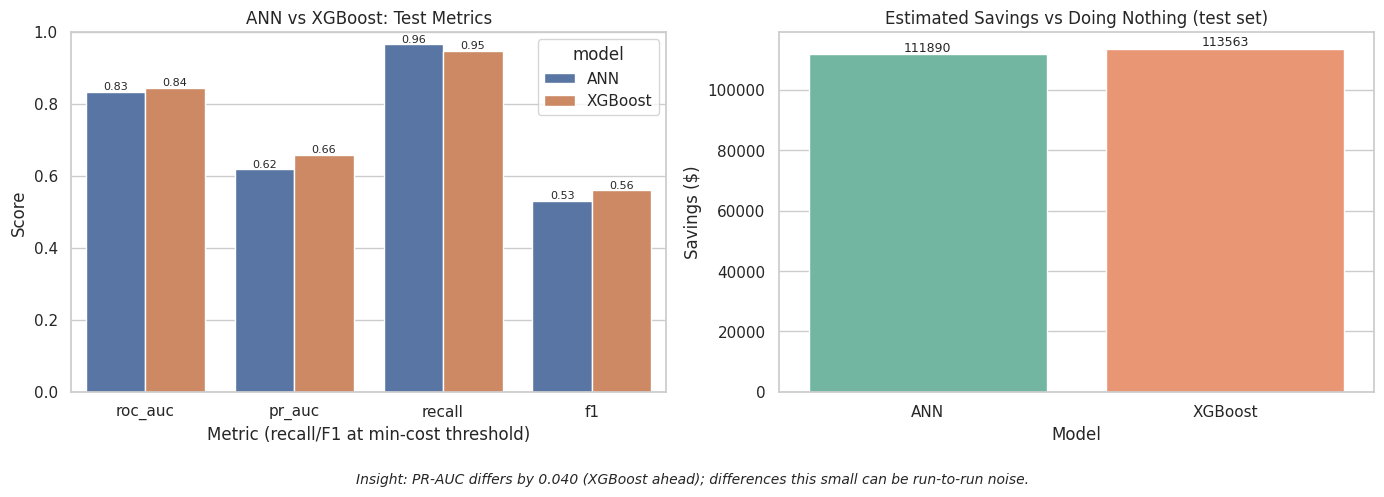

2026-10-30 04:12:08,855 | INFO | VERDICT: Ship XGBoost: ANN PR-AUC difference is -0.040 (margin 0.01), and XGBoost trains faster, works on raw tabular features, and has exact SHAP explanations.


     model           strategy  threshold  precision  recall     f1   tp   fp  \
0      ANN            Default       0.50      0.536   0.717  0.613  268  232   
1      ANN  Min business cost       0.15      0.366   0.965  0.530  361  626   
2  XGBoost            Default       0.50      0.514   0.778  0.619  291  275   
3  XGBoost  Min business cost       0.19      0.397   0.947  0.560  354  537   

    fn   tn  roc_auc  pr_auc  expected_cost  no_model_cost     savings  \
0  106  803    0.834   0.618     239391.037     334092.699   94701.662   
1   13  409    0.834   0.618     222202.774     334092.699  111889.926   
2   83  760    0.845   0.658     232418.133     334092.699  101674.566   
3   20  498    0.845   0.658     220529.309     334092.699  113563.390   

   train_seconds  predict_ms_per_1000_rows  
0            7.1                     103.9  
1            7.1                     103.9  
2            2.3                       4.9  
3            2.3                       4.9  
Shi

In [ ]:
"""Module 10: Deep Learning - Keras ANN baseline vs XGBoost on Telco churn.

TensorFlow/Keras and xgboost are pre-installed in Colab. References globally loaded components
from prior cells instead of external files.
"""
import logging
import time
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers

# Fallback configurations if notebook state is cleared
if "SEED" not in globals():
    SEED = 42

logger = logging.getLogger(__name__)
sns.set_theme(style="whitegrid", context="notebook")


# ---------- data ----------
def prepare_data(df: pd.DataFrame):
    """80/20 stratified test split, then a stratified validation split from the training part.
    The preprocessor is fitted on the sub-training rows only (no leakage)."""
    X, y = prepare_xy(df)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=SEED)
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
    prep = build_preprocessor(X_tr)
    return {
        "Xtr": prep.fit_transform(X_tr).astype("float32"),
        "Xval": prep.transform(X_val).astype("float32"),
        "Xte": prep.transform(X_test).astype("float32"),
        "ytr": y_tr.to_numpy(), "yval": y_val.to_numpy(), "yte": y_test.to_numpy(),
    }


# ---------- ANN ----------
def build_ann(n_features: int, lr: float = 1e-3) -> keras.Model:
    """Dense(64) - BatchNorm - Dropout - Dense(32) - BatchNorm - Dense(1, sigmoid)."""
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.BatchNormalization(),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model


def train_ann(d: dict, max_epochs: int = 100, batch_size: int = 64):
    keras.utils.set_random_seed(SEED)
    w = compute_class_weight("balanced", classes=np.array([0, 1]), y=d["ytr"])
    class_weight = {0: float(w[0]), 1: float(w[1])}
    logger.info("Class weights: %s", {k: round(v, 2) for k, v in class_weight.items()})

    model = build_ann(d["Xtr"].shape[1])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    t0 = time.time()
    history = model.fit(d["Xtr"], d["ytr"], validation_data=(d["Xval"], d["yval"]),
                        epochs=max_epochs, batch_size=batch_size, class_weight=class_weight,
                        callbacks=[stop], verbose=0)
    secs = time.time() - t0
    logger.info("ANN trained for %s epochs in %.1fs", len(history.history["loss"]), secs)
    return model, history, secs


# ---------- XGBoost (same data, same early-stopping treatment) ----------
def train_xgb(d: dict):
    from xgboost import XGBClassifier
    pos_weight = float((d["ytr"] == 0).sum() / (d["ytr"] == 1).sum())
    model = XGBClassifier(n_estimators=1000, learning_rate=0.03, max_depth=4, subsample=0.85,
                          colsample_bytree=0.85, scale_pos_weight=pos_weight,
                          eval_metric="logloss", early_stopping_rounds=30, random_state=SEED)
    t0 = time.time()
    model.fit(d["Xtr"], d["ytr"], eval_set=[(d["Xval"], d["yval"])], verbose=False)
    secs = time.time() - t0
    logger.info("XGBoost used %s trees in %.1fs", model.best_iteration + 1, secs)
    return model, secs


# ---------- plots ----------
def plot_training_curves(history, max_epochs: int, save_dir=None):
    h = history.history
    epochs = np.arange(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for ax, (key, title, ylabel) in zip(axes, [
            ("loss", "Loss Curve", "Binary cross-entropy"),
            ("accuracy", "Accuracy Curve", "Accuracy"),
            ("auc", "ROC-AUC Curve", "ROC-AUC")]):
        ax.plot(epochs, h[key], label="Train")
        ax.plot(epochs, h[f"val_{key}"], label="Validation")
        ax.axvline(best, ls="--", color="grey", label=f"Best epoch ({best})")
        ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
        ax.legend()
    stopped = len(epochs) < max_epochs
    msg = (f"Validation loss is lowest at epoch {best}; early stopping ended training at epoch "
           f"{len(epochs)} and restored the best weights." if stopped else
           f"Training hit the {max_epochs}-epoch limit before early stopping, so try more epochs.")
    _footer(fig, msg, "ann_training_curves", save_dir)


def plot_model_comparison(comparison: pd.DataFrame, save_dir=None):
    at = comparison[comparison["strategy"] == "Min business cost"]
    long = at.melt(id_vars="model", value_vars=["roc_auc", "pr_auc", "recall", "f1"],
                   var_name="metric", value_name="score")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(data=long, x="metric", y="score", hue="model", ax=ax1)
    ax1.set(title="ANN vs XGBoost: Test Metrics", xlabel="Metric (recall/F1 at min-cost threshold)",
            ylabel="Score", ylim=(0, 1))
    for c in ax1.containers:
        ax1.bar_label(c, fmt="%.2f", fontsize=8)
    sns.barplot(data=at, x="model", y="savings", ax=ax2, palette="Set2")
    ax2.set(title="Estimated Savings vs Doing Nothing (test set)", xlabel="Model", ylabel="Savings ($)")
    for c in ax2.containers:
        ax2.bar_label(c, fmt="%.0f", fontsize=9)
    a = at.set_index("model")
    d = a.loc["ANN", "pr_auc"] - a.loc["XGBoost", "pr_auc"]
    _footer(fig, f"PR-AUC differs by {abs(d):.3f} ({'ANN' if d > 0 else 'XGBoost'} ahead); "
                 f"differences this small can be run-to-run noise.", "ann_vs_xgb", save_dir)


# ---------- decision ----------
def production_verdict(comparison: pd.DataFrame, margin: float = 0.01) -> str:
    """Rule: the ANN must beat XGBoost by more than `margin` PR-AUC AND save more money
    to justify its extra cost. Otherwise ship the simpler tree model."""
    a = comparison[comparison["strategy"] == "Min business cost"].set_index("model")
    ann, xgb = a.loc["ANN"], a.loc["XGBoost"]
    d_pr = ann["pr_auc"] - xgb["pr_auc"]
    if d_pr > margin and ann["savings"] > xgb["savings"]:
        return (f"ANN is clearly ahead (PR-AUC +{d_pr:.3f}, higher savings). Consider it, "
                f"but weigh the extra serving and maintenance cost.")
    return (f"Ship XGBoost: ANN PR-AUC difference is {d_pr:+.3f} (margin {margin}), "
            f"and XGBoost trains faster, works on raw tabular features, and has exact SHAP explanations.")


# ---------- run everything ----------
def run_ann_vs_xgb(df: pd.DataFrame, cfg: CostConfig = None, max_epochs: int = 100,
                   save_dir: str = None) -> dict:
    cfg = cfg or CostConfig()
    if cfg.loss_per_churner is None:
        avg = df.loc[df["Churn_flag"] == 1, "MonthlyCharges"].mean()
        cfg = replace(cfg, loss_per_churner=cfg.months_lost * avg)

    d = prepare_data(df)
    ann, history, ann_secs = train_ann(d, max_epochs)
    xgb, xgb_secs = train_xgb(d)

    def ann_proba(X):
        return ann.predict(X, verbose=0).ravel()

    def xgb_proba(X):
        return xgb.predict_proba(X)[:, 1]

    frames = []
    for name, fn, secs in [("ANN", ann_proba, ann_secs), ("XGBoost", xgb_proba, xgb_secs)]:
        # thresholds chosen on the VALIDATION split, then evaluated once on the test set
        _, t_cost, _ = choose_thresholds(d["yval"], fn(d["Xval"]), cfg)
        t0 = time.time()
        p_test = fn(d["Xte"])
        ms = (time.time() - t0) / len(p_test) * 1000 * 1000      # ms per 1000 rows
        res = evaluate_thresholds(d["yte"], p_test, {"Default": 0.5, "Min business cost": t_cost}, cfg)
        res.insert(0, "model", name)
        res["train_seconds"] = round(secs, 1)
        res["predict_ms_per_1000_rows"] = round(ms, 1)
        frames.append(res)
    comparison = pd.concat(frames, ignore_index=True)

    plot_training_curves(history, max_epochs, save_dir)
    plot_model_comparison(comparison, save_dir)
    verdict = production_verdict(comparison)
    logger.info("VERDICT: %s", verdict)
    return {"ann": ann, "xgb": xgb, "history": history, "comparison": comparison,
            "verdict": verdict, "cfg": cfg}


if __name__ == "__main__":
    logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
    if 'clean' in globals():
        out = run_ann_vs_xgb(clean)
        print(out["comparison"])
        print(out["verdict"])
    else:
        logger.error("Clean DataFrame not loaded.")

In [39]:
import joblib
import os

# Get the best trained model
pipeline = result["best_pipe"]

# Create folder
os.makedirs("model_files", exist_ok=True)

# Save model
joblib.dump(
    pipeline,
    "model_files/churn_model.pkl"
)

print("Model saved successfully!")
print("Model:", pipeline)

Model saved successfully!
Model: Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('oh',
                                                                   OneHotEncoder(handle

In [40]:
import os

print(os.path.exists("model_files/churn_model.pkl"))

True


In [51]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
import os

st.set_page_config(
    page_title="Customer Churn Prediction",
    page_icon="📊",
    layout="wide"
)

# Load trained model
@st.cache_resource
def load_model():
    return joblib.load("model_files/churn_model.pkl")

model = load_model()

# Get original feature names
features = list(model.feature_names_in_)

st.title("📊 Telco Customer Churn Prediction")
st.write("Predict whether a telecom customer is likely to leave.")

# --- Sidebar threshold adjustment addition ---
st.sidebar.header("⚙️ Model Parameters")
threshold = st.sidebar.slider(
    "Decision Threshold",
    min_value=0.0,
    max_value=1.0,
    value=0.29,  # Defaulting to your business cost-tuned optimal threshold!
    step=0.01,
    help="Adjust the probability cutoff for flagging a customer as likely to churn. Lower thresholds catch more churners but increase false positives."
)

st.divider()

# Input form
with st.form("churn_form"):

    customer_data = {}

    categorical_options = {
        "gender": ["Male", "Female"],
        "SeniorCitizen": [0, 1],
        "Partner": ["Yes", "No"],
        "Dependents": ["Yes", "No"],
        "PhoneService": ["Yes", "No"],
        "MultipleLines": ["Yes", "No", "No phone service"],
        "InternetService": ["DSL", "Fiber optic", "No"],
        "OnlineSecurity": ["Yes", "No", "No internet service"],
        "OnlineBackup": ["Yes", "No", "No internet service"],
        "DeviceProtection": ["Yes", "No", "No internet service"],
        "TechSupport": ["Yes", "No", "No internet service"],
        "StreamingTV": ["Yes", "No", "No internet service"],
        "StreamingMovies": ["Yes", "No", "No internet service"],
        "Contract": ["Month-to-month", "One year", "Two year"],
        "PaperlessBilling": ["Yes", "No"],
        "PaymentMethod": [
            "Electronic check",
            "Mailed check",
            "Bank transfer (automatic)",
            "Credit card (automatic)"
        ]
    }

    numeric_options = {
        "tenure": (0, 72, 12),
        "MonthlyCharges": (0.0, 150.0, 70.0),
        "TotalCharges": (0.0, 10000.0, 1000.0)
    }

    for feature in features:

        if feature in categorical_options:
            customer_data[feature] = st.selectbox(
                feature,
                categorical_options[feature]
            )

        elif feature in numeric_options:
            low, high, default = numeric_options[feature]

            if feature == "tenure":
                customer_data[feature] = st.slider(
                    feature,
                    int(low),
                    int(high),
                    int(default)
                )
            else:
                customer_data[feature] = st.number_input(
                    feature,
                    min_value=float(low),
                    max_value=float(high),
                    value=float(default)
                )

        else:
            customer_data[feature] = st.text_input(feature)

    submit = st.form_submit_button("Predict Churn")

# Prediction
if submit:
    try:
        input_df = pd.DataFrame(
            [customer_data],
            columns=features
        )

        st.subheader("Prediction Result")

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(input_df)[0]
            classes = list(model.classes_)

            churn_indices = [
                i for i, value in enumerate(classes)
                if str(value).strip().lower() in
                ["yes", "1", "true", "churn"]
            ]

            if churn_indices:
                churn_probability = float(probabilities[churn_indices[0]])

                # Apply the dynamically adjusted slider threshold
                is_churn = churn_probability >= threshold

                st.metric(
                    "Churn Probability",
                    f"{churn_probability * 100:.2f}%"
                )
                st.progress(churn_probability)

                if is_churn:
                    st.error(f"🚨 Customer is flagged as likely to Churn (Probability exceeds threshold of {threshold:.2f}).")
                else:
                    st.success(f"✅ Customer is likely to Stay (Probability is below threshold of {threshold:.2f}).")
        else:
            # Fallback for models without predict_proba
            prediction = model.predict(input_df)[0]
            if str(prediction).lower() in ["yes", "1", "true", "churn"]:
                st.error("Customer is likely to churn.")
            else:
                st.success("Customer is likely to stay.")

    except Exception as e:
        st.error(f"Prediction error: {e}")

st.divider()
st.caption("Telco Customer Churn Prediction | Machine Learning Project")

Overwriting app.py


In [52]:
import subprocess
import time
import os
from pyngrok import ngrok

print("Stopping old processes...")
try:
    ngrok.kill()
except:
    pass
os.system("pkill -f 'streamlit run app.py'")
time.sleep(2)

print("Spinning up the modified Streamlit server...")
with open("streamlit.log", "w") as log_file:
    process = subprocess.Popen(
        [
            "streamlit",
            "run",
            "app.py",
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true"
        ],
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

time.sleep(5)
print("Re-opening ngrok tunnel...")
public_url = ngrok.connect(8501)
print("\n🎉 Done! View your threshold-adjustable application here:")
print(public_url)

2026-10-30 06:28:22,184 | INFO | Killing ngrok process: 35094


Stopping old processes...
Spinning up the modified Streamlit server...


2026-10-30 06:28:29,218 | INFO | Opening tunnel named: http-8501-35890d52-226e-4c02-8f9f-6100144bd7e7
2026-10-30 06:28:29,238 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg="no configuration paths supplied"
2026-10-30 06:28:29,239 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg="using configuration at default config path" path=/root/.config/ngrok/ngrok.yml
2026-10-30 06:28:29,240 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg="open config file" path=/root/.config/ngrok/ngrok.yml err=<nil>
2026-10-30 06:28:29,258 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg="FIPS 140 mode" enabled=false
2026-10-30 06:28:29,266 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg="starting web service" obj=web addr=127.0.0.1:4040 allow_hosts=[]


Re-opening ngrok tunnel...


2026-10-30 06:28:29,459 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg="client session established" obj=tunnels.session
2026-10-30 06:28:29,461 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg="tunnel session started" obj=tunnels.session
2026-10-30 06:28:29,464 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg=start pg=/api/endpoints id=37dd379fe29ec790
2026-10-30 06:28:29,467 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg=end pg=/api/endpoints id=37dd379fe29ec790 status=200 dur=123.497µs
2026-10-30 06:28:29,468 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg=start pg=/api/endpoints id=e07ac59b694d40f8
2026-10-30 06:28:29,472 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg=end pg=/api/endpoints id=e07ac59b694d40f8 status=200 dur=45.522µs
2026-10-30 06:28:29,473 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg=start pg=/api/endpoints id=a8e4655a421a02b0
2026-10-30 06:28:29,477 | INFO | t=2026-10-30T06:28:29+0000 lvl=info msg=end pg=/api/endpoints id=a8e4655a421a02b0 status=200 dur=


🎉 Done! View your threshold-adjustable application here:
NgrokTunnel: "https://deserve-revival-slashed.ngrok-free.dev" -> "http://localhost:8501"


In [43]:
!pip install -q streamlit pyngrok joblib
import subprocess
import time
import os

# Stop old Streamlit processes
os.system("pkill -f 'streamlit run app.py'")

time.sleep(2)

# Start the application
log_file = open("streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(8)

print("Streamlit started!")
print("Process ID:", process.pid)

Streamlit started!
Process ID: 33479


In [44]:
import requests

response = requests.get("http://127.0.0.1:8501")

print("Status code:", response.status_code)

Status code: 200


In [46]:
from pyngrok import ngrok
from getpass import getpass
import sys

# 1. Kill any existing active tunnels
try:
    ngrok.kill()
except Exception:
    pass

# 2. Try to set the auth token, but gracefully pass if it's already set in the configuration file
try:
    # We pull the token from the global environment if you provided it before
    token = globals().get('NGROK_AUTH_TOKEN', '')
    if not token:
        token = getpass("Enter ngrok authentication token: ")

    ngrok.set_auth_token(token)
    print("ngrok configured successfully!")
except Exception as e:
    if "already set" in str(e):
        print("ngrok was already configured! Proceeding to open tunnel.")
    else:
        print(f"Setup warning: {e}. Attempting tunnel anyway...")

# 3. Connect the tunnel to Streamlit's port (8501)
try:
    public_url = ngrok.connect(8501)
    print("\n🎉 Connection successful!")
    print("Open your Streamlit app here:")
    print(public_url)
except Exception as e:
    print(f"\nFailed to connect: {e}")

2026-10-30 06:21:35,497 | INFO | Killing ngrok process: 25533
2026-10-30 06:21:35,517 | INFO | Updating authtoken for default "config_path" of "ngrok_path": /root/.config/ngrok/ngrok
2026-10-30 06:21:35,572 | INFO | Opening tunnel named: http-8501-eb180c8e-af0b-48b8-aec3-053f517ecb6c
2026-10-30 06:21:35,606 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg="no configuration paths supplied"
2026-10-30 06:21:35,608 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg="using configuration at default config path" path=/root/.config/ngrok/ngrok.yml
2026-10-30 06:21:35,612 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg="open config file" path=/root/.config/ngrok/ngrok.yml err=<nil>
2026-10-30 06:21:35,670 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg="FIPS 140 mode" enabled=false
2026-10-30 06:21:35,682 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg="starting web service" obj=web addr=127.0.0.1:4040 allow_hosts=[]


ngrok was already configured! Proceeding to open tunnel.


2026-10-30 06:21:35,893 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg="client session established" obj=tunnels.session
2026-10-30 06:21:35,896 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg="tunnel session started" obj=tunnels.session
2026-10-30 06:21:35,914 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg=start pg=/api/endpoints id=e3f995b578f46817
2026-10-30 06:21:35,929 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg=end pg=/api/endpoints id=e3f995b578f46817 status=200 dur=120.124µs
2026-10-30 06:21:35,931 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg=start pg=/api/endpoints id=7988edef2195fb88
2026-10-30 06:21:35,942 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg=end pg=/api/endpoints id=7988edef2195fb88 status=200 dur=47.459µs
2026-10-30 06:21:35,943 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg=start pg=/api/endpoints id=a40df99c22f23baa
2026-10-30 06:21:35,944 | INFO | t=2026-10-30T06:21:35+0000 lvl=info msg=end pg=/api/endpoints id=a40df99c22f23baa status=200 dur=


🎉 Connection successful!
Open your Streamlit app here:
NgrokTunnel: "https://deserve-revival-slashed.ngrok-free.dev" -> "http://localhost:8501"


2026-10-30 06:21:36,134 | INFO | t=2026-10-30T06:21:36+0000 lvl=info msg=end pg=/api/endpoints id=c902ef7731e5e38b status=201 dur=191.459396ms


In [47]:
# Close any previous tunnels
ngrok.kill()

# Connect ngrok to Streamlit port 8501
public_url = ngrok.connect(8501)

print("Your deployed application URL:")
print(public_url)

2026-10-30 06:22:45,749 | INFO | Killing ngrok process: 33877
2026-10-30 06:22:45,771 | INFO | Opening tunnel named: http-8501-885d7ffa-041b-4f08-b9ea-5c746251d699
2026-10-30 06:22:45,825 | INFO | t=2026-10-30T06:22:45+0000 lvl=info msg="no configuration paths supplied"
2026-10-30 06:22:45,834 | INFO | t=2026-10-30T06:22:45+0000 lvl=info msg="using configuration at default config path" path=/root/.config/ngrok/ngrok.yml
2026-10-30 06:22:45,835 | INFO | t=2026-10-30T06:22:45+0000 lvl=info msg="open config file" path=/root/.config/ngrok/ngrok.yml err=<nil>
2026-10-30 06:22:45,896 | INFO | t=2026-10-30T06:22:45+0000 lvl=info msg="FIPS 140 mode" enabled=false
2026-10-30 06:22:45,908 | INFO | t=2026-10-30T06:22:45+0000 lvl=info msg="starting web service" obj=web addr=127.0.0.1:4040 allow_hosts=[]
2026-10-30 06:22:46,119 | INFO | t=2026-10-30T06:22:46+0000 lvl=info msg="client session established" obj=tunnels.session
2026-10-30 06:22:46,121 | INFO | t=2026-10-30T06:22:46+0000 lvl=info msg="t

Your deployed application URL:
NgrokTunnel: "https://deserve-revival-slashed.ngrok-free.dev" -> "http://localhost:8501"


2026-10-30 06:22:46,331 | INFO | t=2026-10-30T06:22:46+0000 lvl=info msg=end pg=/api/endpoints id=1d7ebcd69e21aeb0 status=201 dur=177.025019ms


In [48]:
import subprocess
import time
import os
from pyngrok import ngrok

print("1. Cleaning up existing Streamlit and ngrok processes...")
try:
    ngrok.kill()
    print("   - Active ngrok tunnels killed successfully.")
except Exception as e:
    print(f"   - No active ngrok processes or warning killing them: {e}")

os.system("pkill -f 'streamlit run app.py'")
time.sleep(2)

print("2. Launching Streamlit server headlessly on port 8501...")
with open("streamlit.log", "w") as log_file:
    process = subprocess.Popen(
        [
            "streamlit",
            "run",
            "app.py",
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true"
        ],
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

time.sleep(5)
print(f"   - Streamlit server started! PID: {process.pid}")

2026-10-30 06:26:15,319 | INFO | Killing ngrok process: 34199


1. Cleaning up existing Streamlit and ngrok processes...
   - Active ngrok tunnels killed successfully.
2. Launching Streamlit server headlessly on port 8501...
   - Streamlit server started! PID: 35063


In [49]:
import requests

print("3. Verifying local Streamlit server health...")
try:
    response = requests.get("http://127.0.0.1:8501", timeout=5)
    print(f"   - Local healthcheck success! Status code: {response.status_code}")
except Exception as e:
    print(f"   - Local healthcheck warning: {e}")

3. Verifying local Streamlit server health...
   - Local healthcheck success! Status code: 200


In [50]:
print("4. Initiating fresh secure tunnel through ngrok...")
try:
    public_url = ngrok.connect(8501)
    print("\n🎉 Connection successful!")
    print("Open your Streamlit app here:")
    print(public_url)
except Exception as e:
    print(f"\nTunnel connection failed: {e}")

2026-10-30 06:26:23,583 | INFO | Opening tunnel named: http-8501-291fe6be-bba8-4d94-868f-4937d5d6755b
2026-10-30 06:26:23,606 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg="no configuration paths supplied"
2026-10-30 06:26:23,607 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg="using configuration at default config path" path=/root/.config/ngrok/ngrok.yml
2026-10-30 06:26:23,608 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg="open config file" path=/root/.config/ngrok/ngrok.yml err=<nil>
2026-10-30 06:26:23,627 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg="FIPS 140 mode" enabled=false
2026-10-30 06:26:23,634 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg="starting web service" obj=web addr=127.0.0.1:4040 allow_hosts=[]


4. Initiating fresh secure tunnel through ngrok...


2026-10-30 06:26:23,840 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg="client session established" obj=tunnels.session
2026-10-30 06:26:23,842 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg="tunnel session started" obj=tunnels.session
2026-10-30 06:26:23,846 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg=start pg=/api/endpoints id=580a57de951a6fc2
2026-10-30 06:26:23,849 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg=end pg=/api/endpoints id=580a57de951a6fc2 status=200 dur=88.455µs
2026-10-30 06:26:23,853 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg=start pg=/api/endpoints id=42251eacff47bb4d
2026-10-30 06:26:23,855 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg=end pg=/api/endpoints id=42251eacff47bb4d status=200 dur=48.418µs
2026-10-30 06:26:23,858 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg=start pg=/api/endpoints id=6dc58d2b0b72d740
2026-10-30 06:26:23,861 | INFO | t=2026-10-30T06:26:23+0000 lvl=info msg=end pg=/api/endpoints id=6dc58d2b0b72d740 status=200 dur=6


🎉 Connection successful!
Open your Streamlit app here:
NgrokTunnel: "https://deserve-revival-slashed.ngrok-free.dev" -> "http://localhost:8501"


2026-10-30 06:26:24,118 | INFO | t=2026-10-30T06:26:24+0000 lvl=info msg=end pg=/api/endpoints id=fe38a7d9c2b22178 status=201 dur=253.538456ms


In [53]:
import os

print("App file:", os.path.exists("app.py"))
print("Model file:", os.path.exists("model_files/churn_model.pkl"))

App file: True
Model file: True


In [54]:
import subprocess
import time

# Start Streamlit
with open("streamlit.log", "w") as log:
    process = subprocess.Popen(
        [
            "streamlit", "run", "app.py",
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(10)

print("Streamlit process:", process.poll())

Streamlit process: 1


In [55]:
import requests

try:
    response = requests.get("http://127.0.0.1:8501", timeout=10)
    print("Status:", response.status_code)
except Exception as e:
    print("Error:", e)

Status: 200


In [58]:
from pyngrok import ngrok
from getpass import getpass

# Kill any existing tunnels before re-establishing
try:
    ngrok.kill()
except Exception:
    pass

token = getpass("Enter your new ngrok token (leave blank to skip if already set): ")
if token.strip():
    try:
        ngrok.set_auth_token(token)
    except Exception as e:
        if "already set" in str(e):
            print("ngrok auth token was already configured! Proceeding...")
        else:
            raise e
else:
    print("Using already configured ngrok token.")

try:
    public_url = ngrok.connect(8501, "http")
    print("\n🎉 Connection successful!")
    print("OPEN THIS URL:")
    print(public_url)
except Exception as e:
    print(f"Failed to connect: {e}")

2026-10-30 06:36:03,078 | INFO | Killing ngrok process: 35623


Enter your new ngrok token (leave blank to skip if already set): ··········


2026-10-30 06:36:49,230 | INFO | Updating authtoken for default "config_path" of "ngrok_path": /root/.config/ngrok/ngrok
2026-10-30 06:36:49,251 | INFO | Opening tunnel named: http-8501-4eeda47e-3da1-4bcf-9139-318838e5aa87
2026-10-30 06:36:49,277 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg="no configuration paths supplied"
2026-10-30 06:36:49,278 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg="using configuration at default config path" path=/root/.config/ngrok/ngrok.yml
2026-10-30 06:36:49,281 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg="open config file" path=/root/.config/ngrok/ngrok.yml err=<nil>
2026-10-30 06:36:49,298 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg="FIPS 140 mode" enabled=false
2026-10-30 06:36:49,304 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg="starting web service" obj=web addr=127.0.0.1:4040 allow_hosts=[]


ngrok auth token was already configured! Proceeding...


2026-10-30 06:36:49,506 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg="client session established" obj=tunnels.session
2026-10-30 06:36:49,507 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg="tunnel session started" obj=tunnels.session
2026-10-30 06:36:49,511 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg=start pg=/api/endpoints id=a8d06ff1eaa8d3ce
2026-10-30 06:36:49,514 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg=end pg=/api/endpoints id=a8d06ff1eaa8d3ce status=200 dur=138.196µs
2026-10-30 06:36:49,516 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg=start pg=/api/endpoints id=59bf313a4154ab05
2026-10-30 06:36:49,520 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg=end pg=/api/endpoints id=59bf313a4154ab05 status=200 dur=52.058µs
2026-10-30 06:36:49,521 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg=start pg=/api/endpoints id=530b36e5a90055cd
2026-10-30 06:36:49,523 | INFO | t=2026-10-30T06:36:49+0000 lvl=info msg=end pg=/api/endpoints id=530b36e5a90055cd status=200 dur=


🎉 Connection successful!
OPEN THIS URL:
NgrokTunnel: "https://deserve-revival-slashed.ngrok-free.dev" -> "http://localhost:8501"


## Project Summary – Telco Customer Churn Prediction

The Telco Customer Churn Prediction project is a Machine Learning-based application designed to predict whether a telecommunications customer is likely to leave the company. The project uses the IBM Telco Customer Churn dataset and applies Python, SQL, Pandas, NumPy, and Scikit-learn for data cleaning, exploratory data analysis, feature engineering, and model development.

Multiple classification algorithms, including Logistic Regression, Decision Tree, Random Forest, and XGBoost, are evaluated to identify a suitable prediction model. Model performance is measured using accuracy, precision, recall, and F1-score. Power BI is used to visualize customer churn patterns, while Streamlit provides an interactive web application where users can enter customer details and receive churn predictions.

The main objective is to help telecommunications companies identify customers at risk of leaving and develop better customer retention strategies.